In [122]:
import pickle
from catboost import CatBoostRegressor, Pool
import numpy as np
version = ""
# load all inputs
with open(f'candidates{version}.pkl', 'rb') as f:
    candidates = pickle.load(f)
with open(f'existing_stores{version}.pkl', 'rb') as f:
    existing_stores = pickle.load(f)
with open(f'ownership_map{version}.pkl', 'rb') as f:
    ownership_map = pickle.load(f)
with open(f'distance_matrix{version}.pkl', 'rb') as f:
    distance_matrix = pickle.load(f)
with open(f'build_out_cost_by_region{version}.pkl', 'rb') as f:
    build_out_cost_by_region = pickle.load(f)

In [11]:
[x for x in  candidates.keys() if len(x) == 5]

[]

In [12]:
len(candidates)

2627

In [123]:
"""
Greedy + Monte Carlo site selection simulator

Flow (per Monte Carlo run):
 - For year = 1..N:
   - Update candidate attributes (sample sales/cost -> IRR; update impact maps if needed)
   - Pool selection using probability buckets + carryover
   - Greedy selection sorted by IRR (ties by lower impact) while enforcing constraints:
       * fill exactly N_target sites (if enough candidates), otherwise choose all
       * region cap <= 25% of N_target
       * one special store-type cap <= 12.5% of N_target
       * exclusivity: no two within EXCLUSIVITY_MILES
   - Assign owners (simulate owner-get rules), compute actual applied impacts
   - Update rolling 2-year impact history for existing stores
   - Update state (existing sites, ownership, remaining candidates, carryover)
 - Repeat for many Monte Carlo runs; aggregate outputs

Dependencies: numpy, pandas, multiprocessing (optional), collections
"""
import math
import random
import numpy as np
import pandas as pd
from collections import defaultdict, Counter
from multiprocessing import Pool, cpu_count
import functools

# -------------------------
# CONFIGURATION (tuneable)
# -------------------------
N_YEARS = 10
YEARLY_CAPS = [100] * N_YEARS          # number to open each year
REGION_SHARE = 0.25                    # per-region cap as fraction of yearly cap
SPECIAL_STORE_TYPE = "YES"             # SSAM store_type gets 12.5% cap -> YES = SSAM, NO = not SSAM
SPECIAL_TYPE_SHARE = 0.125
EXCLUSIVITY_MILES = 10.0               # exclusivity radius (miles) -> need to change it to 10 minute driving distance
USE_PROB_YEARS = 5                     # apply pool probability buckets for first 5 years
PREFILTER_MULT = 3                     # keep multiplier*N_target for pre-filtering
MC_RUNS = 500                          # number of Monte Carlo simulations
PARALLEL = True                        # run MC sims in parallel
WORKERS = max(1, cpu_count() - 1)

# -------------------------
# Sampling helpers
# -------------------------
def sample_sales_point(row, year, models=None):
    """
    Deterministic point forecast (used for fast scoring / prefilter).
    If CatBoost 'point' model provided in models dict, uses it; otherwise uses row['sales_mean'].

    DEPRECATED since we will use quantile based forecast
    """
    if models and "point" in models:
        X = row.copy(); X["year"] = year
        try:
            return float(models["point"].predict(pd.DataFrame([X]))[0])
        except Exception:
            pass
    return float(row.get("sales_mean", 0.0))

def sample_sales_for_site(row, year, models=None):
    # if models and all(k in models for k in ("q10","q50","q90")):
    # try:
        # q10=float(models["q10"].predict(pd.DataFrame([X]))[0])
        # q50=float(models["q50"].predict(pd.DataFrame([X]))[0])
        # q90=float(models["q90"].predict(pd.DataFrame([X]))[0])
    q10, q50, q90 = sorted(row)
    inflation_factor = 0.04 # 4% inflation
    for _ in range(year - 2025):
        q10 = q10 * (1 + inflation_factor)
        q50 = q50 * (1 + inflation_factor)
        q90 = q90 * (1 + inflation_factor)
    q10,q50,q90 = sorted([q10, q50/1.1, q90/1.1])
    sample = float(np.random.triangular(q10,q50,q90))
    return max(sample,0.0)
    # except Exception:
    #     pass
    # mu = row.get("sales_mean",0.0)
    # sigma = row.get("sales_std", max(1.0, 0.15*abs(mu)))
    # return float(max(np.random.normal(mu, sigma), 0.0))

def sample_build_cost_for_site(region, year, build_cost_lookup=None):
    # sample output
    #  'Southeast Region': {'avg_pct_change': 13.575353503908829,
    # 'last_mean': 4912179.8963636365,
    # 'last_median': 5474106.095,
    # 'std': 1618499.7705548638},
    fixed_rate = 0.046 # 4.6%
    median, std = build_cost_lookup[region]['last_median'], build_cost_lookup[region]['std']
    for _ in range(year - 2024):
        # mean = mean * (1 + build_cost_lookup[region]['avg_pct_change'] / 150)
        median = median * (1 + fixed_rate)
    sigma2 = np.log(1 + (std**2)/(median**2))
    mu = np.log(median) - 0.5*sigma2; sigma=np.sqrt(max(sigma2,1e-12))
    return float(np.random.lognormal(mu, sigma))

def impact_pct_by_distance(features, exist_model):
    # feature list: 'forecast', 'open_year', 'distance', 'density_new', 'density_exist', 'competitor_count_1', 
    #               'boundary_1', 'boundary_2', 'boundary_3', 'year_1', 'year_2', 'year_3', 'closest', 'closer_stores'
    impact = exist_model.predict([features]) +  random.uniform(0.02, 0.05)
    return impact

# -------------------------------
# Categorization Logic
# -------------------------------

def categorize_owner_impacts_single(impact_values):
    """
    Categorize impacts for owners based on past 3 years including current.
    Returns dict of {owner_id: category}
    """
    if sum(i >= 0.05 for i in impact_values) >= 2:
        return "consecutive"
    elif any(i >= 0.15 for i in impact_values):
        return "single"
    return "other"
    
def categorize_owner_impacts(owner_map, owner_id, sites, site, existing_impact_history, impact):
    """
    Categorize impacts for owners based on past 3 years including current.
    Returns dict of {owner_id: category}
    """
    window = 3
    if len(owner_map[owner_id][0]) > 1: # muo
        t = 'multiple_'
        impact_values = existing_impact_history[site][-window:-1] + [impact]
        output = []
        if any(i >= 0.15 for i in impact_values):
            output += [t + "single"]
        elif sum(i >= 0.05 for i in impact_values) >= 2 and len(impact_values) >= 2:
            output += [t + "consecutive"]

        # enterprise
        impact_values = [0, 0, 0]
        for s in sites:
            temp = existing_impact_history[s][-window:]
            for i in range(min(3, len(temp))):
                impact_values[i] = max(existing_impact_history[s][-(i+1)], impact_values[i])
        if sum(i >= 0.05 for i in impact_values) >= 2 and t + "consecutive" not in output and t + "single" not in output:
            output += [t + "enterprise"]
        output = list(set(output))
        if len(output) > 1:
            return t + "combined"
        elif len(output) == 1:
            return output[0]
    else:
        t = 'single_'
        output = []
        impact_values = existing_impact_history[site][-window:-1] + [impact]
        if any(i >= 0.15 for i in impact_values):
            output += [t + "single"]
        elif sum(i >= 0.05 for i in impact_values) >= 2 and len(impact_values) >= 2:
            output += [t + "consecutive"]

        if len(output) > 1:
            return t + "combined"
        elif len(output) == 1:
            return output[0]
    return ['single_', 'multiple_'][len(owner_map[owner_id][0]) > 1] + "other"

# -------------------------------
# Categorization Logic
# -------------------------------
# owner_assignment(ownership_map[owner][0], owner, existing_impact_history, minutes)
def owner_assignment(owner_map, driving_minutes=30):
    # if operator has single unit -> various rules
    # if operator has two units -> 5% probability for driving minutes less than 10 minutes
    # if operator has more than two units -> 0 probability

    # need to introduce enterprise
    prob = random.random()
    # print(prob, owner_map, len(owner_map))
    if len(owner_map) == 1: # operator with single unit
        if driving_minutes <= 5 and prob <= 0.70:
            return [True, 'single']
        elif 5 < driving_minutes <= 10 and prob <= 0.5:
            return [True, 'single']
        elif 10 < driving_minutes <= 15 and prob <= 0.35:
            return [True, 'single']
        elif 15 < driving_minutes <= 20 and prob <= 0.15:
            return [True, 'single']
        return [False, 'single']
    elif len(owner_map) == 2: # operator with 2 units
        if driving_minutes <= 10 and prob <= 0.05: # 5% of probability if the owner has two stores
            return [True, 'multiple']
        return [False, 'multiple']
    return [False, 'multiple'] # operator with more than 2 units, 0 probability
        
# -------------------------------
# Pool Selection
# -------------------------------

def select_from_pool(candidates, year, cap, chosen_stores_list, prob_mode=True):
    """
    Select candidates for a given year with probability buckets if available.
    Returns (chosen_sites, leftovers).
    """
    year_sites = {sid: s for sid, s in candidates.items() if s.get("prod_year") <= year if sid not in chosen_stores_list}
    leftovers = {sid: s for sid, s in candidates.items() if sid not in chosen_stores_list and sid not in year_sites}
    
    probability_buckets = {'>75': 0.9, '50-75': 0.65, '25-50': 0.4, '<25': 0.2}
    # With prob bucket logic
    chosen = {}

    # let's increase the cap little bit for more robust selection
    buffer = random.randint(100, 140)
    cap = int(cap*( 1+buffer/100)) # by 25%

    # print(year, cap, buffer, len(year_sites))
    if len(year_sites) < cap:
        next_year_sites = {sid: s for sid, s in candidates.items() if s.get("prod_year") == year + 1}
        if len(next_year_sites) + len(year_sites) < cap:
            return year_sites | next_year_sites | leftovers, {}
        chosen = year_sites.copy() # choose everything from current year first
        
        site_probs, sids = [], []
        for sid, s in next_year_sites.items():
            try:
                site_probs += [probability_buckets[s['prod_bucket']]]
            except:
                site_probs += [0.65]
            sids += [sid]
        site_probs = np.array(site_probs, dtype=float)
        site_probs /= site_probs.sum() # normalize to 1

        selected_indices = np.random.choice(len(next_year_sites), cap - len(chosen), replace=False, p=site_probs)
        selected_probs = site_probs[selected_indices]
        descending_sort_indices = np.argsort(selected_probs)[::-1]
        sorted_indices = selected_indices[descending_sort_indices]
        for i in sorted_indices:
            sid = sids[i]
            chosen[sid] = next_year_sites[sid]
    else:
        site_probs, sids = [], []
        for sid, s in year_sites.items():
            try:
                site_probs += [probability_buckets[s['prod_bucket']]]
            except:
                site_probs += [0.65]
            sids += [sid]
        site_probs = np.array(site_probs, dtype=float)
        site_probs /= site_probs.sum() # normalize to 1

        selected_indices = np.random.choice(len(year_sites), cap, replace=False, p=site_probs)
        selected_probs = site_probs[selected_indices]
        descending_sort_indices = np.argsort(selected_probs)[::-1]
        sorted_indices = selected_indices[descending_sort_indices]
        for i in sorted_indices:
            sid = sids[i]
            chosen[sid] = year_sites[sid]
        
    # print('chosen size: ', len(chosen), year, cap)
    return chosen, {sid: s for sid, s in candidates.items() if sid not in chosen_stores_list and sid not in chosen}

# -----------------------------
# Candidate Selection
# -----------------------------

def select_candidates(candidates, strategy, N):
    if strategy == "irr":
        chosen = candidates.sort_values("irr", ascending=False).head(N)

    elif strategy == "impact":
        chosen = candidates.sort_values("impact_score", ascending=True).head(N)

    elif strategy == "combined":
        impact_sorted = candidates.sort_values("impact_score", ascending=True)
        subset = impact_sorted.head(min(2 * N, len(impact_sorted)))
        chosen = subset.sort_values("irr", ascending=False).head(N)

    elif strategy == "random":
        chosen = candidates.sample(n=min(N, len(candidates)))

    else:
        raise ValueError(f"Unknown strategy {strategy}")

    return chosen

# -------------------------------
# Simulation Functions
# -------------------------------
import copy
def run_single_mc(candidates_original, existing_stores_original, ownership_map_original, yearly_caps, distance_matrix, build_cost_lookup, region_cap=0.25, years=10, impact_model=None, prod_mode=True, run_number=0):
    results = []
    window = 3
    
    existing_impact_history = defaultdict(list)

    # copy from original
    candidates = copy.deepcopy(candidates_original)
    existing_sites = copy.deepcopy(existing_stores_original)
    ownership_map = copy.deepcopy(ownership_map_original)

    # # pipelines in 2026 and 2027
    pipelines_opened = {}
    for year in [2026, 2027, 2028]:
        pipelines_opened[year] = yearly_caps.get(year, 0)[0]
        for sid in existing_sites.keys():
            # add last element to impact with 0
            existing_impact_history[sid] += [0]
        cap = yearly_caps.get(year, 0)[0]
        ssam_cap = yearly_caps.get(year, 0)[1]
        for sid, site in existing_sites.items():
            if site['opened_dt'] is not None and int(str(site['opened_dt'])[:4]) == year and random.random() <= 0.9:
                nearby_store = site['nearby_stores']
                impact_pct, impact_score, loss_sales = 0.0, 0, 0
                for id_ in nearby_store:
                    try:
                        miles, minutes = distance_matrix[sid][id_]
                        closest = [0, 1][minutes < min(site['distances'])]
                        closer = len([x for x in site['distances'] if x < minutes])
                        if id_ in existing_sites:
                            ex_site = existing_sites[id_]
                            base_pct = impact_pct_by_distance([ex_site['sales'], year, miles, str(int(site['density_classification'])),
                                                              str(int(ex_site['density_classification'])), ex_site['competitor_count']] +
                                                              ex_site['boundary'] + ex_site['years'] + [closest, closer], impact_model)[0]
                            impact_pct += -base_pct / 100 if base_pct < 0 else 0.0
                            # print(id_, existing_impact_history[id_])
                            existing_impact_history[id_][-1] += -base_pct / 100 if base_pct < 0 else 0.0
                    except:
                        continue
                cap -= 1
                pipelines_opened[year] += 1
                if cap == 0:
                    break
                
    print(pipelines_opened)                
    # chosen stores
    chosen_stores_list = set()
    for year in range(1, years + 1):
        year += 2027
        cap = yearly_caps.get(year, 0)[0]
        if year in pipelines_opened:
            cap -= pipelines_opened[year]
        cap = max(0, cap)
        ssam_cap = yearly_caps.get(year, 0)[1]
        print(year, cap, ssam_cap)

        # update year (last time operator received the store)
        for key in ownership_map.keys():
            ownership_map[key][1] += 1 # add one year to # of years since operator received a new store
            
        # update existing sites
        for sid in existing_sites.keys():
            # add last element to impact with 0
            existing_impact_history[sid] += [0]
            if year > 2028: # from the second year, we need to update
                # boundary and years features
                nearby_store = existing_sites[sid]['nearby_stores']
                boundary, years = existing_sites[sid]['boundary'], existing_sites[sid]['years'][1:] + [0]
                # print(sid, nearby_store)
                add_distance, add_nearby = [], []
                for id_ in nearby_store:
                    if id_ in current_chosen_ids:
                        miles, minutes = distance_matrix[sid][id_]
                        if miles // 5 < 3:
                            boundary[int(miles // 5)] += 1
                            years[-1] += 1
                            add_distance += [miles]
                        if miles // 5 < 4 :
                            add_nearby += [id_]
                existing_sites[sid]['boundary'] = boundary
                existing_sites[sid]['years'] = years
                existing_sites[sid]['distances'] += add_distance
                existing_sites[sid]['nearby_stores'] += add_nearby
    
        # choose the pool if needed; otherwise take everything
        chosen_pool, remainders = select_from_pool(candidates, year, cap, chosen_stores_list, prob_mode=prob_mode)
        
        impact_history = {}
        scored = []
        for sid, site in chosen_pool.items():
            sales = sample_sales_for_site(site['sales_forecast'], year)
            build_cost = sample_build_cost_for_site(site['region'], year, build_cost_lookup)
            nearby_store = site['nearby_stores']
            impact_pct, impact_score, loss_sales = 0.0, 0, 0
            impact_history[sid] = {} # history
            for id_ in nearby_store:
                try:
                    miles, minutes = distance_matrix[sid][id_]
                    closest = [0, 1][minutes < min(site['distances'])]
                    closer = len([x for x in site['distances'] if x < minutes])
                    if id_ in existing_sites:
                        ex_site = existing_sites[id_]
                        base_pct = impact_pct_by_distance([ex_site['sales'], year, miles, str(int(site['density_classification'])),
                                                          str(int(ex_site['density_classification'])), ex_site['competitor_count']] +
                                                          ex_site['boundary'] + ex_site['years'] + [closest, closer], impact_model)[0]
                        impact_pct += -base_pct / 100 if base_pct < 0 else 0.0
                        impact_history[sid][id_] = -base_pct / 100 if base_pct < 0 else 0.0
                        loss_sales += (-base_pct / 100 if base_pct < 0 else 0.0) * ex_site['sales']
                        ## impact score owner_map, owner_id, sites, site, existing_impact_history
                        site_category = categorize_owner_impacts_single(existing_impact_history[id_][-window:-1] + [impact_history[sid][id_]]) # site category
                        impact_score += [0, 1]['other' not in site_category] # if the impact is single or consecutive, we add 1 to impact score; 0 otherwise
                except:
                    continue
            irr = -2.592859e-8 * build_cost + 2.395230e-8 * sales - 1.968792e-1 * impact_pct + 0.1835
            # print(build_cost, sales, impact_pct, loss_sales, irr)
            scored.append((sid, impact_score, irr, sales, build_cost, impact_pct, loss_sales))

        scored_temp = []
        for sid, site in remainders.items():
            sales = sample_sales_for_site(site['sales_forecast'], year)
            build_cost = sample_build_cost_for_site(site['region'], year, build_cost_lookup)
            nearby_store = site['nearby_stores']
            impact_pct, impact_score, loss_sales = 0.0, 0, 0
            impact_history[sid] = {} # history
            for id_ in nearby_store:
                try:
                    miles, minutes = distance_matrix[sid][id_]
                    closest = [0, 1][minutes < min(site['distances'])]
                    closer = len([x for x in site['distances'] if x < minutes])
                    if id_ in existing_sites:
                        ex_site = existing_sites[id_]
                        base_pct = impact_pct_by_distance([ex_site['sales'], year, miles, str(int(site['density_classification'])),
                                                          str(int(ex_site['density_classification'])), ex_site['competitor_count']] +
                                                          ex_site['boundary'] + ex_site['years'] + [closest, closer], impact_model)[0]
                        impact_pct += -base_pct / 100 if base_pct < 0 else 0.0
                        impact_history[sid][id_] = -base_pct / 100 if base_pct < 0 else 0.0
                        loss_sales += (-base_pct / 100 if base_pct < 0 else 0.0) * ex_site['sales']
                        ## impact score owner_map, owner_id, sites, site, existing_impact_history
                        site_category = categorize_owner_impacts_single(existing_impact_history[id_][-window:-1] + [impact_history[sid][id_]]) # site category
                        impact_score += [0, 1]['other' not in site_category] # if the impact is single or consecutive, we add 1 to impact score; 0 otherwise
                except:
                    continue
            irr = -2.592859e-8 * build_cost + 2.395230e-8 * sales - 1.968792e-1 * impact_pct + 0.1835
            # print(build_cost, sales, impact_pct, loss_sales, irr)
            scored_temp.append((sid, impact_score, irr, sales, build_cost, impact_pct, loss_sales))
        
        # scored.sort(key=lambda x: x[2], reverse=True)
        chosen, current_chosen_ids = [], set()

        # with open('temp.pkl', 'wb') as f:
        #     pickle.dump(existing_impact_history, f)
        ## to calculate the total dots available that don't violate a growth principle
        extra_operator_metrics = defaultdict(int)
        for sid, impact_score, irr, sales, build_cost, impact_pct, loss_sales in scored + scored_temp:
            ## let's assume every store is impacted so need to update the impact history first
            ## -> if the store gets assigned to existing operator, we will force it to be zero impact from next loop
            ## -> otherwise, the impact percentage remains the same
            # temp_impact_history = {xx:yy for xx,yy in existing_impact_history.items()} # this is hypothetical case; we should not update the actual one
            temp_impact_history = existing_impact_history.copy()
            for site in impact_history[sid].keys():
                temp_impact_history[site][-1] += impact_history[sid][site] # add impact to the existing store for history
            category, assigned = set(), False
            for site in impact_history[sid].keys():
                distance, minutes = distance_matrix[sid][site]
                if minutes <= 20: # drive time less than 20 minutes
                    site_category = categorize_owner_impacts(ownership_map, existing_sites[site]['owner_id'], impact_history[sid], site, temp_impact_history, impact_history[sid][site]) # site category
                    # print(sid, site, site_category, existing_sites[site]['owner_id'], temp_impact_history[site], impact_history[sid])
                    if not assigned:
                        owner = existing_sites[site]['owner_id']
                        owner_assigned, owner_type = owner_assignment(ownership_map[owner][0], minutes)
                        if owner_assigned:
                            assigned = True
                            # temp_impact_history[site][-1] = 0
                    if site_category not in ('single_other', 'multiple_other'):
                        category.add(site_category)
            for site in impact_history[sid].keys():
                temp_impact_history[site][-1] -= impact_history[sid][site] # add impact to the existing store for history
            # at the dot level
            category = ', '.join(sorted(category))
            if category.strip() != '':
                extra_operator_metrics[category] += 1

        # apply region and ssam constraints
        region_limit = defaultdict(int)
        ssam_limit = defaultdict(int)
        # print('-----------------------')
        # print('pool selection size: ', len(scored))
        for sid, impact_score, irr, sales, build_cost, impact_pct, loss_sales in scored:
            region, ssam = chosen_pool[sid]['region'], chosen_pool[sid]['store_type']
            # print(chosen_pool[sid]['prod_year'], chosen_pool[sid]['prod_bucket'])
            if region_limit[region] <= (int(cap * region_cap) + 1):
                if (ssam == 'Yes' and ssam_limit[ssam] <= int(ssam_cap)) or (ssam == 'No'):
                    region_limit[region] += 1
                    ssam_limit[ssam] += 1
                    chosen += [(sid, impact_score, irr, sales, build_cost, impact_pct, loss_sales)]
            if len(chosen) == cap:
                break
        
        impact_stores_list, irrs, sales_, costs_, impacts_, losses_ = set(), [], [], [], [], []
        owner_assignments = defaultdict(str)
        site_category_map = defaultdict(str)
        impact_scores = [] # 1 if impacted; 0 if not
        operator_metrics = {'new': 0, 'single': 0, 'multiple': 0, 'single_consecutive': 0, 'single_single': 0, 'single_combined': 0, 'single_other': 0,
                           'multiple_consecutive': 0, 'multiple_single': 0, 'multiple_enterprise': 0, 'multiple_combined': 0, 'multiple_other': 0}
        force_zero_impact = set() # if existing operator receives the new site, existing store impact is zero
        
        ### measures the impact percentages for consecutive cases
        consecutives = {'single': [], 'multiple': []}
        ### counts of new/single unit operator when multi-unit operator is impacted
        multi_operators_case = {'new': 0, 'single': 0}
        order = 1
        for sid, impact_score, irr, sales, build_cost, impact_pct, loss_sales in chosen:
            #print(sid, impact_score, irr, sales, impact_pct, loss_sales)
            # 115C94D4-A878-4BB9-A25C-06998DED93CD 0 0.10958709149209686 7199999.210307003 0.4599328784744113 4195578.206981415
            muo_impacted, suo_received = False, False
            
            chosen_stores_list.add(sid)
            current_chosen_ids.add(sid)
            site_data = candidates[sid]
            # based on impact history for sid, let's loop through the list of stores that was impacted
            new_site_assigned = False
            operator_received, operator_type = '', ''
            for site in impact_history[sid].keys():
                distance, minutes = distance_matrix[sid][site]
                if minutes <= 20: # drive time less than 20 minutes
                    impact_stores_list.add(site)
                    existing_impact_history[site][-1] += impact_history[sid][site] # add impact to the existing store for history
                    site_category = categorize_owner_impacts(ownership_map, existing_sites[site]['owner_id'], impact_history[sid], site, existing_impact_history, impact_history[sid][site]) # site category
                    # print(existing_impact_history[site], impact_history[sid][site], site_category, impact_history[sid])
                    # if 'multiple' in site_category:
                    #     print(site, site_category,  ownership_map[existing_sites[site]['owner_id']])
                    #     # 04156 multiple_other [{'01362', '04156'}, 3]
                    #     for ss in ownership_map[existing_sites[site]['owner_id']][0]:
                    #         print(ss, existing_impact_history[ss])
                    site_category_map[site] = site_category
                    if not new_site_assigned: # new store has not been assigned to 
                        # owner assignment
                        owner = existing_sites[site]['owner_id']
                        owner_assigned, owner_type = owner_assignment(ownership_map[owner][0], minutes)
                        # print(sid, site, owner_assigned, owner_type, ownership_map[owner], minutes, site_category)
                        if owner_assigned: # if operator receives the new store for store within 10 minutes driving time
                            operator_received, operator_type = owner, owner_type
                            ownership_map[operator_received][1] = 0
                            ownership_map[operator_received][0].add(sid)
                            if owner_type == 'single':
                                operator_metrics['single'] += 1
                                suo_received = True # single unit operator received the new store
                            elif owner_type == 'multiple':
                                operator_metrics['multiple'] += 1
                            new_site_assigned, assigned_owner = True, owner
                            force_zero_impact.add(site) # those existing store will have zero impact at the end after receiving new site
                            new_site_assigned = True
                        else:
                            if 'consecutive' in site_category:
                                consecutives[owner_type] += [sum(existing_impact_history[site][-window:-1] + [impact_history[sid][site]])]
                            if owner_type == 'multiple' and site_category != 'other':
                                muo_impacted = True
                        owner_assignments[site] = site_category # category by impact history for existing stores

            if not new_site_assigned: # going to assign a new operator
                operator_metrics['new'] += 1
                operator_received = max(ownership_map.keys()) + 1  
                ownership_map[operator_received] = [set(), 0]
            
            if muo_impacted: # if multiple unit operator was impacted but not received....
                if not new_site_assigned: # if no existing operator received the new store
                    multi_operators_case['new'] += 1
                elif suo_received:
                    multi_operators_case['single'] += 1  

            # add it to existing now!
            existing_sites[sid] = {"site_id": sid, "owner_id": operator_received, "opened_dt": str(year)+f'-01-{str(order).zfill(2)}', 
                                   "sales": sales, "density_classification": candidates[sid]['density_classification'], 
                                   "competitor_count": candidates[sid]['competitor_count'], "boundary": candidates[sid]['boundary'], 
                                   "years": candidates[sid]['years'], 
                                   "distances": candidates[sid]['distances'], "nearby_stores": candidates[sid]['nearby_stores'],
                                   "impacts": impact_history[sid]
                                  } # needs to update this
            order += 1
            # remove it from candidates
            del candidates[sid]
            irrs.append(irr)
            impact_scores.append(impact_score)
            sales_.append(sales)
            costs_.append(build_cost)
            impacts_.append(impact_pct)
            losses_.append(loss_sales)
            if len(irrs) == cap:
                break

        # let's loop through impacted stores and collect relevant metrics
        for sid in impact_stores_list:
            if sid not in force_zero_impact: # if existing operator didn't receive a new store
                operator_metrics[site_category_map[sid]] += 1

        # for existing stores where the operator receives a new unit, impact score must be zero
        for sid in force_zero_impact:
            existing_impact_history[sid][-1] = 0
            
        results.append({
            "run_number": run_number,
            "year": year,
            "avg_IRR": np.mean(irrs) if irrs else 0,
            "std_IRR": np.std(irrs) if irrs else 0,
            "irr_q25": np.percentile(irrs, 25) if irrs else 0,
            "irr_q50": np.percentile(irrs, 50) if irrs else 0,
            "irr_q75": np.percentile(irrs, 75) if irrs else 0,
            "irr": irrs,
            "sales": sales_,
            "build_cost": costs_,
            "impact_pct": impacts_,
            "impact_loss": losses_,
            "region": region_limit,
            "ssam": ssam_limit,
            "avg_impact_pct": np.mean(impact_scores) if impact_scores else 0,
            "impact_score": impact_scores,
            "number_of_impacted_stores": len(impact_stores_list),
            "new_owner_sites": operator_metrics['new'],
            'suo_impacted': sum([y for x,y in operator_metrics.items() if 'single' in x]),
            'suo_not_receive_single': operator_metrics['single_single'],
            'suo_not_receive_consecutive': operator_metrics['single_consecutive'],
            'suo_not_receive_combined': operator_metrics['single_combined'],
            'suo_not_receive_other': operator_metrics['single_other'],
            'muo_impacted': sum([y for x,y in operator_metrics.items() if 'multiple' in x]),
            'muo_not_receive_single': operator_metrics['multiple_single'],
            'muo_not_receive_consecutive': operator_metrics['multiple_consecutive'],
            'muo_not_receive_enterpise': operator_metrics['multiple_enterprise'],
            'muo_not_receive_combined': operator_metrics['multiple_combined'],
            'muo_not_receive_other': operator_metrics['multiple_other'],
            "total_sites": len(irrs),
            "network_size": len(existing_sites),
            "consecutive": consecutives,
            "muo_analysis": multi_operators_case,
            "new_metric": extra_operator_metrics,
            "pool_size": len(chosen_pool) + len(remainders),
            "openings": existing_sites
        })
        # print(results[-1])

    return results


from concurrent.futures import ThreadPoolExecutor, as_completed
def run_monte_carlo(candidates, existing_sites, ownership_map, yearly_caps_list, distance_matrix, build_cost_lookup, region_cap=0.25, years=10, runs=100, impact_model=None, prod_mode=True):
    # run_single_mc(candidates, existing_sites, ownership_map, yearly_caps, distance_matrix, build_cost_lookup, region_cap=0.25, ssam_cap=0.125, years=10, prob_mode=True):
    all_runs = []
    max_workers = 6
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        futures = {}
        for label, cap in yearly_caps_list.items():
            for r in range(runs):
                # print(cap, r, len(candidates), len(existing_sites))
                future = executor.submit(
                    run_single_mc,
                    candidates.copy(),
                    existing_sites.copy(),
                    ownership_map.copy(),
                    cap,
                    distance_matrix,
                    build_cost_lookup,
                    region_cap,
                    years,
                    impact_model,
                    prod_mode,
                    r
                )
                futures[future] = (label, r)
        for future in as_completed(futures):
            yearly_caps, r = futures[future]
            # try:
            results = future.result()
            # add metadata to each result row
            all_runs.extend([
                dict(res, yearly_caps=yearly_caps)
                for res in results
            ])
            # except Exception as e:
            #     print(f"Error in run {r} (yearly_caps={yearly_caps}): {e}")

    df = pd.DataFrame(all_runs)
    return df

In [124]:
# %%capture
# -------------------------
# Run!
# -------------------------
prob_mode = True # use prod bucket for pool selection
# 82 stores already opened in 2026
yearly_caps = {"Current Plan": {2026: [0, 8], 2027: [0, 22], 2028: [0, 20], 2029: [119+20+5-51, 20], 2030: [117+20+5-9, 20], 2031: [119+20+5-6, 20], 2032: [109+20+5-1, 20], 2033: [119+10+5,10], 2034: [119+10+5, 10], 2035: [119+10+5, 10]},
               # "Scenario #2 (Adjusted Openings)": {2026: 175, 2027: 140, 2028:120, 2029:140, 2030:135, 2031:135, 2032:125, 2033:125, 2034:125, 2035:125, 2036:125, 2037:125},
               # "Scenario #3 (Pull Other Levers)": {2026: 175, 2027: 150, 2028:130, 2029:155, 2030:150, 2031:150, 2032:140, 2033:140, 2034:140, 2035:140, 2036:140, 2037:140}
              }
region_cap = 0.25
year, run = 8, 1
impact_model = CatBoostRegressor()
impact_model.load_model('impact_catboost_model.cbm')
# Run with probability pool selection
df_prob = run_monte_carlo(candidates, existing_stores, ownership_map, yearly_caps, distance_matrix, build_out_cost_by_region, region_cap, year, run, impact_model, prob_mode)
# with open(f"yearcap_yes_probmode_yes_all_sim.pkl", "wb") as f:
#     pickle.dump(df_prob, f)

{2026: 172, 2027: 171, 2028: 197}
2028 0 20
2029 93 20
2030 133 20
2031 138 20
2032 133 20
2033 134 10
2034 134 10
2035 134 10


In [125]:
pd.set_option('display.max_columns', None)
df_prob.head(20)

,run_number,year,avg_IRR,std_IRR,irr_q25,irr_q50,irr_q75,irr,sales,build_cost,impact_pct,impact_loss,region,ssam,avg_impact_pct,impact_score,number_of_impacted_stores,new_owner_sites,suo_impacted,suo_not_receive_single,suo_not_receive_consecutive,suo_not_receive_combined,suo_not_receive_other,muo_impacted,muo_not_receive_single,muo_not_receive_consecutive,muo_not_receive_enterpise,muo_not_receive_combined,muo_not_receive_other,total_sites,network_size,consecutive,muo_analysis,new_metric,pool_size,openings,yearly_caps
0,0,2028,0.000000,0.000000,0.000000,0.000000,0.000000,[],[],[],[],[],{},{},0.000000,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,3448,"{'single': [], 'multiple': []}","{'new': 0, 'single': 0}","{'multiple_single': 114, 'single_consecutive, ...",2627,"{'00090': {'site_id': '00090', 'owner_id': 417...",Current Plan
1,0,2029,0.169473,0.043444,0.144305,0.174623,0.207296,"[0.15146306306883273, 0.17214803403173531, 0.0...","[9080566.94674087, 9616495.029939767, 7721368....","[9058181.953731416, 7941736.624181767, 1043152...","[0.07452038908065337, 0.18169063597118368, 0.2...","[707605.1762207497, 1966889.5198763823, 226125...","{'West Region': 25, 'Northeast Region': 25, 'M...","{'No': 74, 'Yes': 19}",0.215054,"[0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, ...",149,62,107,4,2,0,66,46,4,1,7,0,34,93,3541,"{'single': [0.16132423781454475, 0.21297735530...","{'new': 23, 'single': 6}","{'single_consecutive': 32, 'single_single': 18...",2627,"{'00090': {'site_id': '00090', 'owner_id': 417...",Current Plan
2,0,2030,0.168294,0.041946,0.141465,0.172182,0.201294,"[0.08377892743380862, 0.17077423149733698, 0.1...","[9851018.180672318, 10813471.486751094, 874506...","[10660234.354277784, 9551591.703173395, 745123...","[0.3010514541867578, 0.122277906837221, 0.0, 0...","[2670483.2526310217, 1413227.1552725534, 0, 24...","{'West Region': 35, 'Atlantic Region': 6, 'Nor...","{'No': 112, 'Yes': 21}",0.180451,"[0, 0, 0, 0, 2, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, ...",210,102,111,4,3,0,73,100,1,7,5,0,86,133,3674,"{'single': [0.23838620724183196, 0.14497516517...","{'new': 42, 'single': 7}","{'multiple_consecutive, multiple_enterprise, s...",2534,"{'00090': {'site_id': '00090', 'owner_id': 417...",Current Plan
3,0,2031,0.160930,0.042895,0.135014,0.163516,0.194700,"[0.09151737017453916, 0.12924573279606263, 0.1...","[9725993.00181085, 9765313.234288055, 7749273....","[7869172.7943379395, 10544862.117139539, 83894...","[0.6141124962880393, 0.07488131272238072, 0.0,...","[6110002.618537366, 773975.7987560384, 0, 7971...","{'Southwest Region': 6, 'West Region': 36, 'No...","{'No': 125, 'Yes': 13}",0.275362,"[0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, ...",269,102,152,6,7,0,100,121,4,10,16,0,90,138,3812,"{'single': [0.20375005612199704, 0.21105658402...","{'new': 46, 'single': 12}","{'single_single': 156, 'multiple_consecutive, ...",2401,"{'00090': {'site_id': '00090', 'owner_id': 417...",Current Plan
4,0,2032,0.165313,0.049110,0.137203,0.171849,0.199317,"[0.12616290763964602, 0.0696400455618071, 0.21...","[8844797.567605572, 8496731.01688569, 9097560....","[10381989.037541686, 11610897.136580134, 71778...","[0.0, 0.08290369621262059, 0.0, 0.183681992312...","[0, 914889.2427017292, 0, 1552280.3647543164, ...","{'West Region': 35, 'Southeast Region': 24, 'M...","{'No': 124, 'Yes': 9}",0.436090,"[0, 0, 0, 0, 0, 1, 0, 1, 0, 5, 1, 0, 2, 0, 0, ...",219,90,117,5,6,0,61,110,7,16,23,0,59,133,3945,"{'single': [0.1224033402710693, 0.174047713168...","{'new': 43, 'single': 13}","{'multiple_consecutive, multiple_enterprise': ...",2263,"{'00090': {'site_id': '00090', 'owner_id': 417...",Current Plan
5,0,2033,0.170497,0.042783,0.142998,0.173500,0.203145,"[0.12423328786632654, 0.2328515481303658, 0.19...","[10818173.95563165, 10422588.508795107, 105118...","[11407714.607211286, 7724809.509844047, 929009...","[0.11479580008328442, 0.0, 0.0, 0.0, 0.0904760...","[937391.0943719936, 0, 0, 0, 712562.988185198,...","{'West Region': 34, 'Midwest Region': 15, 'Nor...","{'No': 123, 'Yes

In [127]:
last = df_prob.openings.values[-1]
for a, b in last.items():
    print(a, b, b['opened_dt'])
    if pd.to_datetime(b['opened_dt']) >= pd.to_datetime('2026-06-01'):
        print(a, b)

00090 {'site_id': '00090', 'owner_id': 417.0, 'opened_dt': datetime.date(1972, 1, 25), 'sales': 7500000, 'density_classification': 4, 'competitor_count': 2, 'boundary': [0, 0, 0], 'years': [0, 0, 0], 'distances': [], 'nearby_stores': []} 1972-01-25
00801 {'site_id': '00801', 'owner_id': 413.0, 'opened_dt': datetime.date(1986, 4, 16), 'sales': 9932241.6, 'density_classification': 3.0, 'competitor_count': 16.0, 'boundary': [0, 0, 0], 'years': [0, 0, 0], 'distances': [], 'nearby_stores': []} 1986-04-16
00802 {'site_id': '00802', 'owner_id': 20230.0, 'opened_dt': datetime.date(1987, 8, 12), 'sales': 8588272.56, 'density_classification': 5.0, 'competitor_count': 20.0, 'boundary': [0, 0, 0], 'years': [0, 0, 0], 'distances': [], 'nearby_stores': []} 1987-08-12
00803 {'site_id': '00803', 'owner_id': 14904.0, 'opened_dt': datetime.date(1987, 9, 30), 'sales': 0.0, 'density_classification': 4, 'competitor_count': 2, 'boundary': [0, 0, 0], 'years': [0, 0, 0], 'distances': [], 'nearby_stores': []} 

TypeError: '>=' not supported between instances of 'NoneType' and 'Timestamp'

## Sales

In [166]:
# df = spark.sql("""select location_num, open_date, location_status, location_type, 
# date_trunc('month', trans_date) as month, sum(sls_net) as total_net_sales, sum(trans_cnt) as trans_cnt from dx_prod.sales_ltd.daily_sales_extended group by 1, 2, 3, 4, 5""")
actual_sales = pd.read_parquet("monthly_sales.parquet")
actual_sales = actual_sales[actual_sales['month'] >= '2020-01-01']
actual_sales.head(2)

,location_num,open_date,location_status,location_type,month,total_net_sales,trans_cnt
20,00000,None,None,None,2020-01-01,30069.46,846
21,00000,None,None,None,2020-02-01,17981.19,593


In [167]:
print(set(actual_sales.location_status))

{'closed', 'future', 'open', 'remodel', None}


In [168]:
esf_sales = pd.read_parquet("esf_sales.parquet")
esf_sales.head(2)

,location_number,month,sales_forecast_30
0,05473,2027-01-01,346845
1,05893,2031-08-01,514642


In [169]:
## merge
actual_sales = actual_sales[["location_num", "month", "total_net_sales"]]
esf_sales.columns = ["location_num", "month", "total_net_sales"]

actual_sales['source'] = 'history'
esf_sales['source'] = 'esf'
sales = pd.concat([actual_sales, esf_sales])

In [170]:
actual_sales[actual_sales['location_num'] == '05677'].sort_values('month').head(10)

,location_num,month,total_net_sales,source
267549,05677,2025-08-01,904.82,history
267550,05677,2025-09-01,328093.05,history
267551,05677,2025-10-01,1251911.43,history
267552,05677,2025-11-01,1128049.47,history
267553,05677,2025-12-01,1252426.48,history
267554,05677,2026-01-01,1098536.54,history
267555,05677,2026-02-01,1173009.68,history
267556,05677,2026-03-01,1292071.81,history
267557,05677,2026-04-01,1292011.77,history
267558,05677,2026-05-01,1351497.79,history


In [171]:
esf_sales[esf_sales['location_num'] == '05677'].sort_values('month').head(20)

,location_num,month,total_net_sales,source
220016,05677,2026-09-01,1387370,esf
39208,05677,2026-10-01,1450370,esf
57442,05677,2026-11-01,1252509,esf
16151,05677,2026-12-01,1358451,esf
271991,05677,2027-01-01,1233964,esf
79735,05677,2027-02-01,1234123,esf
51307,05677,2027-03-01,1385731,esf
63273,05677,2027-04-01,1314751,esf
87743,05677,2027-05-01,1304224,esf
331767,05677,2027-06-01,1234910,esf


In [186]:
sales_records = {}
for _, row in sales.iterrows():
    if row.location_num not in sales_records:
        sales_records[row.location_num] = {}
    if str(row.month)[:10] in sales_records[row.location_num] and row.source == 'history':
        sales_records[row.location_num][str(row.month)[:10]] = row.total_net_sales
    elif str(row.month)[:10] not in sales_records[row.location_num]:
        sales_records[row.location_num][str(row.month)[:10]] = row.total_net_sales

In [187]:
loc = pd.read_parquet('loc_attributes.parquet')
print(set(loc.status))
loc = loc[loc['status'].isin(["open", "remodel", "closed"])]
loc = loc[loc["subtype_id"].isin(["FSU", "DTO"])]

test = pd.merge(loc[["location_number", "status", "subtype_id"]], esf_sales, left_on="location_number", right_on="location_num", how="left")
test.head()

{'never opened', 'terminated', 'closed', 'future', 'open', 'remodel'}


,location_number,status,subtype_id,location_num,month,total_net_sales,source
0,01015,closed,FSU,NaN,NaN,NaN,NaN
1,01642,open,FSU,01642,2035-04-01,1278175.0,esf
2,01642,open,FSU,01642,2031-09-01,1027546.0,esf
3,01642,open,FSU,01642,2036-04-01,1365122.0,esf
4,01642,open,FSU,01642,2031-05-01,1040668.0,esf


In [188]:
loc[loc['location_number'] == '01864'].head()

,location_id,location_number,location_name,is_confidential,status,operator_guid,operator_id,operator,operating_as,is_multi_unit,projected_open_dt,opened_dt,age,is_relocated,relocated_from,is_temp_closed,temp_closed_reason,closed_dt,terminated_dt,concept_type_id,concept_type,location_type_code,subtype_id,subtype,format_type,is_foodtruck,prototype,prototype_edition,building_square_footage,noncustomer_square_footage,total_site_square_footage,total_site_acreage,elevation_meters,elevation_feet,has_sprinkler_system,fire_suppression_method,restaurant_type,deliveries_fulfilled_by,deliveries_fulfilled_for,has_dining_room,maximum_occupancy,has_outside_seating,total_interior_seats,total_exterior_seats,has_cross_parking,total_parking_spaces,total_handicap_spaces,has_drivethru,drivethru_type,has_bypass_lane,has_drivethru_door,total_drivethru_lanes,total_fulfillment_lanes,total_approach_lanes,total_order_points,total_pickup_windows,total_drivethru_capacity,kitchen_type,kitchen_layout,kitchen_installed_dt,has_remote_freezer,playground,land_dimension_notes,is_land_purchased,site_layout,is_mall_food_court,mall_cookline,has_mall_dining_room,has_mall_restroom,has_remote_mall_storage,remote_mall_storage_square_footage,mall_location,address1,address2,address3,city,county,state,zip,zip_extension,country,country_code,hex_id,hex_string,hex_boundary_wkt,latitude,longitude,gmt_offset,timezone,timezone_id,email_address,voicemail_number,phone_number,fax_number,price_group,region_id,region,dma_id,dma,dma_marketing_code,submarket,operator_team_id,operator_team,service_team_id,service_team,is_smart_safe_participant,distribution_center,opportunity_type,building_construction_dt,parent_location_number,accountant_id,accountant_guid,accountant,accounts_receivable_id,accounts_receivable_guid,accounts_receivable,area_director_id,area_director_guid,area_director,business_development_representative_licensee_id,business_development_representative_licensee_guid,business_development_representative_licensee,business_relationship_director_id,business_relationship_director_guid,business_relationship_director,business_relationship_lead_id,business_relationship_lead_guid,business_relationship_lead,dc_existing_restaurant_id,dc_existing_restaurant_guid,dc_existing_restaurant,dc_new_restaurant_id,dc_new_restaurant_guid,dc_new_restaurant,deal_real_estate_developer_id,deal_real_estate_developer_guid,deal_real_estate_developer,digital_field_service_tech_id,digital_field_service_tech_guid,digital_field_service_tech,director_satellite_restaurant_id,director_satellite_restaurant_guid,director_satellite_restaurant,equipment_representative_id,equipment_representative_guid,equipment_representative,erqa_representative_id,erqa_representative_guid,erqa_representative,existing_restaurant_real_estate_developer_id,existing_restaurant_real_estate_developer_guid,existing_restaurant_real_estate_developer,facilities_area_field_consultant_id,facilities_area_field_consultant_guid,facilities_area_field_consultant,facilities_project_coordinator_id,facilities_project_coordinator_guid,facilities_project_coordinator,facilities_regional_director_id,facilities_regional_director_guid,facilities_regional_director,financial_return_consultant_id,financial_return_consultant_guid,financial_return_consultant,fm_tech_consultant_id,fm_tech_consultant_guid,fm_tech_consultant,food_safety_report_representative_id,food_safety_report_representative_guid,food_safety_report_representative,lease_accountant_id,lease_accountant_guid,lease_accountant,new_restaurant_specialist_id,new_restaurant_specialist_guid,new_restaurant_specialist,operations_lead_id,operations_lead_guid,operations_lead,payroll_services_accountant_id,payroll_services_accountant_guid,payroll_services_accountant,payroll_tax_accountant_id,payroll_tax_accountant_guid,payroll_tax_accountant,property_management_analyst_id,property_management_analyst_guid,property_management_analyst,property_tax_accountant_id,property_tax_accountant_guid,property_tax_accountant

## Location

In [189]:
loc = pd.read_parquet('loc_attributes.parquet')
loc = loc[loc['status'].isin(["future", "open", "remodel", "closed"])]
loc = loc[["location_number", "subtype_id", "submarket", "dma"]]
loc = loc[loc["subtype_id"].isin(["FSU", "DTO"])]
print(loc.shape)
loc.head()

(3445, 4)


,location_number,subtype_id,submarket,dma
0,07047,FSU,None,"Miami-Ft. Lauderdale, FL"
1,07048,FSU,None,"Ft. Myers-Naples, FL"
2,07049,FSU,None,"Ft. Myers-Naples, FL"
3,07050,FSU,None,"Indianapolis, IN"
5,01015,FSU,DFW-North Irving,"Dallas-Ft. Worth, TX"


In [211]:
## closed
closed_loc = pd.read_parquet('loc_attributes.parquet')
closed_loc = closed_loc[closed_loc['status'] == 'closed']
closed_loc = closed_loc[["location_number", "closed_dt"]]
closed = {}
for _, row in closed_loc.iterrows():
    closed[row.location_number] = row.closed_dt

In [190]:
strategy = pd.read_parquet("strategy_attributes.parquet")
strategy.head(2)

,location_num,location_name,subtype,location_type,location_status,state,dma,submarket,region
0,A3BFE78C-9CA9-4005-B5D2-F68A1D7895D9,Lake Underhill & Chickasaw | Orlando,FSU,green,Tier 1,FL,"Orlando-Daytona Beach-Melbourne, FL",Orlando-East Central,Southeast Region
1,3B383839-714C-405C-BA29-C10A8FD0B8DA,"I-44 at Bishop Ave (Rolla, MO)",FSU,green,Tier 1,MO,"St. Louis, MO",N/A,Midwest Region


In [191]:
loc_att = {}
for _, row in loc.iterrows():
    loc_att[row.location_number] = (row.subtype_id, row.submarket, row.dma)
for _, row in strategy.iterrows():
    loc_att[row.location_num] = (row.subtype, row.submarket, row.dma)

In [192]:
loc_att['01864']

('FSU', 'Abilene, TX-South', 'Abilene-Sweetwater, TX')

## Sales impact adjusted

In [193]:
from datetime import datetime
from dateutil.relativedelta import relativedelta

current_date = '2026-06-01'
for key, value in last.items():
    if 'impacts' in value and value['impacts'] != {}:
        if value['opened_dt'] >= current_date:
            for nearby, pct in value['impacts'].items():
                if nearby in sales_records:
                    start_date = value['opened_dt'][:7] + '-01'
                    dt = datetime.strptime(start_date, '%Y-%m-%d')
                    ## first year impact
                    for i in range(12):
                        new_date = str(dt + relativedelta(months=i))[:10]
                        if new_date in sales_records[nearby]:
                            sales_records[nearby][new_date] = sales_records[nearby][new_date] * (1 - pct)
                    ## second year impact
                    for i in range(12, 24):
                        new_date = str(dt + relativedelta(months=i))[:10]
                        if new_date in sales_records[nearby]:
                            sales_records[nearby][new_date] = sales_records[nearby][new_date] * (1 - pct/2)

In [194]:
for key, value in last.items():
    if key in loc_att and loc_att[key][1] == 'Abilene, TX-South':
        print(key, loc_att[key])

01864 ('FSU', 'Abilene, TX-South', 'Abilene-Sweetwater, TX')
05677 ('FSU', 'Abilene, TX-South', 'Abilene-Sweetwater, TX')
2636E6C8-ABC8-4102-AABF-4A80BA7B54FA ('FSU', 'Abilene, TX-South', 'Abilene-Sweetwater, TX')


In [195]:
from collections import defaultdict
history_ = defaultdict(int)
history = defaultdict(int)
for year in range(2027, 2034):
    for key, value in last.items():
        if str(value['opened_dt']).split('-')[0] == str(year):
            if key in loc_att and loc_att[key][0] in ('FSU', 'DTO'):
                print(key, value['opened_dt'], loc_att[key])
                history[str(value['opened_dt'])[:7]] += 1
                history_[str(value['opened_dt'])[:4]] += 1
print(history)

04363 2027-09-30 ('FSU', 'St.Louis-St.Charles-E', 'St. Louis, MO')
04505 2027-10-07 ('FSU', 'Los Angeles, CA-San Fernando Valley NW', 'Los Angeles, CA')
04976 2027-02-23 ('FSU', 'Myrtle Beach', 'Myrtle Beach-Florence, SC')
05098 2027-06-03 ('FSU', 'Portland-Clackamas Happy Valley', 'Portland, OR')
05165 2027-02-01 ('FSU', 'Los Angeles, CA-Palmdale-Lancaster', 'Los Angeles, CA')
05201 2027-05-06 ('FSU', 'Charlotte - South Carolina', 'Charlotte, NC')
05492 2027-08-19 ('FSU', None, 'Savannah, GA')
05722 2027-09-23 ('FSU', 'Chicago-Joliet', 'Chicago, IL')
05730 2027-12-02 ('FSU', 'Lexington | West Lexington', 'Lexington, KY')
05752 2027-01-07 ('FSU', None, 'Portland-Auburn, ME')
05754 2027-08-19 ('FSU', 'Tampa-Apollo Beach', 'Tampa-St. Petersburg (Sarasota), FL')
05764 2027-01-21 ('FSU', 'Tampa-Fort Myers South (Estero)', 'Ft. Myers-Naples, FL')
05813 2027-08-26 ('FSU', 'Phoenix, AZ-Buckeye', 'Phoenix (Prescott), AZ')
05816 2027-05-27 ('FSU', 'Los Angeles, CA-San Fernando Valley NE', 'Los 

In [196]:
history_

defaultdict(int,
            {'2027': 187,
             '2028': 223,
             '2029': 166,
             '2030': 151,
             '2031': 138,
             '2032': 123,
             '2033': 124})

## Re-organize

In [197]:
submarkets = {}
dma = {}

for year in range(2020, 2034):
    for key, value in last.items():
        if str(value['opened_dt']).split('-')[0] <= str(year):
            if key in loc_att and loc_att[key][0] in ('FSU', 'DTO'):
                if loc_att[key][1] not in submarkets:
                    submarkets[loc_att[key][1]] = {}
                if loc_att[key][2] not in dma:
                    dma[loc_att[key][2]] = {}

                if year not in submarkets[loc_att[key][1]]:
                    submarkets[loc_att[key][1]][year] = {'existing': [], 'new': [], 'pipeline': [], 'strategy': []}
                if year not in dma[loc_att[key][2]]:
                    dma[loc_att[key][2]][year] = {'existing': [], 'new': [], 'pipeline': [], 'strategy': []}

                if str(value['opened_dt'])[:4] < str(year): # existing
                    submarkets[loc_att[key][1]][year]['existing'] += [(value['site_id'], value['opened_dt'], value['sales'], value['impacts'] if "impacts" in value else {})]
                    dma[loc_att[key][2]][year]['existing'] += [(value['site_id'], value['opened_dt'], value['sales'], value['impacts'] if "impacts" in value else {})]
                else: # new
                    if str(value['opened_dt'])[:4] < str(current_date): # previous new store
                        submarkets[loc_att[key][1]][year]['new'] += [(value['site_id'], value['opened_dt'], value['sales'], value['impacts'] if "impacts" in value else {})]
                        dma[loc_att[key][2]][year]['new'] += [(value['site_id'], value['opened_dt'], value['sales'], value['impacts'] if "impacts" in value else {})]
                    elif key.isdigit(): # pipelines
                        submarkets[loc_att[key][1]][year]['pipeline'] += [(value['site_id'], value['opened_dt'], value['sales'], value['impacts'] if "impacts" in value else {})]
                        dma[loc_att[key][2]][year]['pipeline'] += [(value['site_id'], value['opened_dt'], value['sales'], value['impacts'] if "impacts" in value else {})]
                    else: # strategy
                        submarkets[loc_att[key][1]][year]['strategy'] += [(value['site_id'], value['opened_dt'], value['sales'], value['impacts'] if "impacts" in value else {})]
                        dma[loc_att[key][2]][year]['strategy'] += [(value['site_id'], value['opened_dt'], value['sales'], value['impacts'] if "impacts" in value else {})]

In [226]:
inflation_rate = 3
def annual_sales(store, year, predicted_sales):
    temp_sales_history = {}
    if store in sales_records:
        for month, sale in sales_records[store].items():
            if str(month)[:4] not in temp_sales_history:
                temp_sales_history[str(month)[:4]] = []
            temp_sales_history[str(month)[:4]] += [sale]
        if str(year) in temp_sales_history:
            if len(temp_sales_history[str(year)]) > 10:
                total_sales = sum(temp_sales_history[str(year)]) / len(temp_sales_history[str(year)]) * 12
            else:
                total_sales = 0
        else:
            last_year = max(temp_sales_history.keys())
            if int(last_year) < int(year) - 1 or (store in closed and int(year) > int(str(closed[store])[:4])):
                total_sales = 0
            else:
                sales_ = sum(temp_sales_history[str(last_year)]) / len(temp_sales_history[str(last_year)]) * 12
                total_sales = sales_ * ((1 + inflation_rate/100) ** (int(year) - int(last_year)))

    else:
        total_sales = predicted_sales * ((1 + inflation_rate/100) ** (int(year) - 2026))
    return total_sales

def impacted_annual_sales(store, year):
    return 0

In [217]:
for month, sale in sales_records['01864'].items():
    if str(month)[:4] == '2027':
        print(month, sale)

In [200]:
submarkets['Abilene, TX-South']

{2020: {'existing': [('01864', datetime.date(2006, 3, 2), 0.0, {})],
  'new': [],
  'pipeline': [],
  'strategy': []},
 2021: {'existing': [('01864', datetime.date(2006, 3, 2), 0.0, {})],
  'new': [],
  'pipeline': [],
  'strategy': []},
 2022: {'existing': [('01864', datetime.date(2006, 3, 2), 0.0, {})],
  'new': [],
  'pipeline': [],
  'strategy': []},
 2023: {'existing': [('01864', datetime.date(2006, 3, 2), 0.0, {})],
  'new': [],
  'pipeline': [],
  'strategy': []},
 2024: {'existing': [('01864', datetime.date(2006, 3, 2), 0.0, {})],
  'new': [],
  'pipeline': [],
  'strategy': []},
 2025: {'existing': [('01864', datetime.date(2006, 3, 2), 0.0, {})],
  'new': [('05677', datetime.date(2025, 9, 23), 14189861.28, {})],
  'pipeline': [],
  'strategy': []},
 2026: {'existing': [('01864', datetime.date(2006, 3, 2), 0.0, {}),
   ('05677', datetime.date(2025, 9, 23), 14189861.28, {})],
  'new': [],
  'pipeline': [],
  'strategy': []},
 2027: {'existing': [('01864', datetime.date(2006, 3, 

In [230]:
submarket_output = []
remove = set()
for submarket in submarkets.keys():
    visited = set()
    for year in sorted(submarkets[submarket].keys()):
        #print(submarket, year)
        existing_auv, young_store_auv, maturity = [], [], []
        for store, open_dt, sales, impact in submarkets[submarket][year]["existing"]:
            matured_year = int(year) - int(str(open_dt)[:4])
            annual_sales_ = annual_sales(store, str(year), sales)
            if store == '05677' or store == '01864':
                print(year, store, open_dt, sales, annual_sales_)
            if annual_sales_ >= 3000000:
                if matured_year <= 2: # young store
                    young_store_auv += [annual_sales_]
                else:
                    existing_auv += [annual_sales_]
            if annual_sales_ > 0 or store not in visited or year == min(submarkets[submarket].keys()):
                maturity += [int(year) - int(str(open_dt)[:4])]
            visited.add(store)
        pipeline_auv, strategy_auv, new_auv = [], [], []
        for store, open_dt, sales, impact in submarkets[submarket][year]["new"]:
            new_auv += [annual_sales(store, str(year), sales)]
        for store, open_dt, sales, impact in submarkets[submarket][year]["pipeline"]:
            pipeline_auv += [annual_sales(store, str(year), sales)]
        for store, open_dt, sales, impact in submarkets[submarket][year]["strategy"]:
            strategy_auv += [annual_sales(store, str(year), sales)]
        submarket_output += [['submarket', submarket, year, existing_auv, young_store_auv, maturity, len(existing_auv) + len(young_store_auv), new_auv, len(new_auv), pipeline_auv, len(pipeline_auv), strategy_auv, len(strategy_auv)]]

2020 01864 2006-03-02 0.0 8654406.58
2021 01864 2006-03-02 0.0 10491980.780000001
2022 01864 2006-03-02 0.0 11451222.56
2023 01864 2006-03-02 0.0 12645206.25
2024 01864 2006-03-02 0.0 12988001.2
2025 01864 2006-03-02 0.0 0
2026 01864 2006-03-02 0.0 0
2026 05677 2025-09-23 14189861.28 15982450.900000002
2027 01864 2006-03-02 0.0 0
2027 05677 2025-09-23 14189861.28 15250576.0
2028 01864 2006-03-02 0.0 0
2028 05677 2025-09-23 14189861.28 12028124.0
2029 01864 2006-03-02 0.0 0
2029 05677 2025-09-23 14189861.28 13408176.584044829
2030 01864 2006-03-02 0.0 0
2030 05677 2025-09-23 14189861.28 14978198.203369377
2031 01864 2006-03-02 0.0 0
2031 05677 2025-09-23 14189861.28 16853356.0
2032 01864 2006-03-02 0.0 0
2032 05677 2025-09-23 14189861.28 17418453.0
2033 01864 2006-03-02 0.0 0
2033 05677 2025-09-23 14189861.28 17735988.0


In [231]:
submarket_df = pd.DataFrame(submarket_output, columns=["type", "submarket", "year", "existing_auv", "young_store_auv", "maturity", "number_of_existing_stores", "new_auv", "number_of_new", "pipeline_auv", "number_of_pipeline", "strategy_auv", "number_of_strategy"])

In [233]:
submarket_df[submarket_df['submarket'] == 'Abilene, TX-South'].head(15)

,type,submarket,year,existing_auv,young_store_auv,maturity,number_of_existing_stores,new_auv,number_of_new,pipeline_auv,number_of_pipeline,strategy_auv,number_of_strategy
5264,submarket,"Abilene, TX-South",2020,[8654406.58],[],[14],1,[],0,[],0,[],0
5265,submarket,"Abilene, TX-South",2021,[10491980.780000001],[],[15],1,[],0,[],0,[],0
5266,submarket,"Abilene, TX-South",2022,[11451222.56],[],[16],1,[],0,[],0,[],0
5267,submarket,"Abilene, TX-South",2023,[12645206.25],[],[17],1,[],0,[],0,[],0
5268,submarket,"Abilene, TX-South",2024,[12988001.2],[],[18],1,[],0,[],0,[],0
5269,submarket,"Abilene, TX-South",2025,[],[],[],0,[0],1,[],0,[],0
5270,submarket,"Abilene, TX-South",2026,[],[15982450.900000002],[1],1,[],0,[],0,[],0
5271,submarket,"Abilene, TX-South",2027,[],[15250576.0],[2],1,[],0,[],0,[],0
5272,submarket,"Abilene, TX-South",2028,[12028124.0],[],[3],1,[],0,[],0,[],0
5273,submarket,"Abilene, TX-South",2029,[13408176.584044829],[],[4],1,[],0,[],0,[9647762.17123752],1


In [234]:
def flatten_and_clean(values):

    if values is None:
        return []

    if isinstance(values, float) and np.isnan(values):
        return []

    if not isinstance(values, list):
        values = [values]

    cleaned = []

    for v in values:
        if v is None:
            continue

        if isinstance(v, float) and np.isnan(v):
            continue

        if float(v) > 0:
            cleaned.append(float(v))

    return cleaned
    
def add_details(df, key):
    # average, median
    df["existing_auv_avg"] = df["existing_auv"].apply(
        lambda x: np.mean(flatten_and_clean(x))
    )
    
    df["existing_auv_med"] = df["existing_auv"].apply(
        lambda x: np.median(flatten_and_clean(x))
    )

    df["young_store_auv_avg"] = df["young_store_auv"].apply(
        lambda x: np.mean(flatten_and_clean(x))
    )
    
    df["young_store_auv_med"] = df["young_store_auv"].apply(
        lambda x: np.median(flatten_and_clean(x))
    )

    def combine_auv(existing, young_store, new, pipeline, strategy):
        existing = flatten_and_clean(existing)
        young_store = flatten_and_clean(young_store)
        new = flatten_and_clean(new)
        pipeline = flatten_and_clean(pipeline)
        strategy = flatten_and_clean(strategy)
    
        return existing + young_store + new + pipeline + strategy

    def combine_existing_auv(existing, young_store):
        existing = flatten_and_clean(existing)
        young_store = flatten_and_clean(young_store)
    
        return existing + young_store

    def combine_new_auv( new, pipeline, strategy):
        new = flatten_and_clean(new)
        pipeline = flatten_and_clean(pipeline)
        strategy = flatten_and_clean(strategy)
    
        return new + pipeline + strategy
    
    
    df["combined_auv"] = df.apply(
        lambda row: combine_auv(row["existing_auv"], row["young_store_auv"], row["new_auv"], row["pipeline_auv"], row["strategy_auv"]),
        axis=1
    )

    df["existing_combined_auv"] = df.apply(
        lambda row: combine_existing_auv(row["existing_auv"], row["young_store_auv"]),
        axis=1
    )
    
    df["combined_auv_avg"] = df["combined_auv"].apply(
        lambda x: np.mean(x) if len(x) > 0 else np.nan
    )
    
    df["combined_auv_med"] = df["combined_auv"].apply(
        lambda x: np.median(x) if len(x) > 0 else np.nan
    )

    df["new_combined_auv"] = df.apply(
        lambda row: combine_new_auv(row["new_auv"], row["pipeline_auv"], row["strategy_auv"]),
        axis=1
    )

    # maturity stats
    df["maturity_avg"] = df["maturity"].apply(
        lambda x: np.mean(flatten_and_clean(x))
    )
    
    # df["maturity_min"] = df["maturity"].apply(
    #     lambda x: np.min(flatten_and_clean(x))
    # )
    
    # df["maturity_max"] = df["maturity"].apply(
    #     lambda x: np.max(flatten_and_clean(x))
    # )

    # sales growth
    df = df.sort_values([key, "year"])

    df["young_store_auv_avg"] = df["young_store_auv"].apply(
        lambda x: np.mean(x) if len(x) > 0 else np.nan
    )

    df["existing_auv_avg"] = df["existing_combined_auv"].apply(
        lambda x: np.mean(x) if len(x) > 0 else np.nan
    )

    df["matured_auv_avg"] = df["existing_auv"].apply(
        lambda x: np.mean(x) if len(x) > 0 else np.nan
    )

    df["new_auv_avg"] = df["new_combined_auv"].apply(
        lambda x: np.mean(x) if len(x) > 0 else np.nan
    )
    
    df["sales_growth_rate_matured"] = (
        df.groupby(key)["matured_auv_avg"]
          .pct_change() * 100
    )

    df["sales_growth_rate_young_store"] = (
        df.groupby(key)["young_store_auv_avg"]
          .pct_change() * 100
    )

    df["sales_growth_rate_existing"] = (
        df.groupby(key)["existing_auv_avg"]
          .pct_change() * 100
    )

    df["sales_growth_rate_new"] = (
        df.groupby(key)["new_auv_avg"]
          .pct_change() * 100
    )

    df["sales_growth_rate_combined"] = (
        df.groupby(key)["combined_auv_avg"]
          .pct_change() * 100
    )

    df["number_of_new_stores"] = df["number_of_new"] + df["number_of_pipeline"] + df["number_of_strategy"]
    return df

In [235]:
dma_output = []
for dma_ in dma.keys():
    for year in sorted(dma[dma_].keys()):
        existing_auv, maturity = [], []
        for store, open_dt, sales, impact in dma[dma_][year]["existing"]:
            existing_auv += [annual_sales(store, str(year), sales)]
            maturity += [int(year) - int(str(open_dt)[:4])]
        pipeline_auv, strategy_auv = [], []
        for store, open_dt, sales, impact in dma[dma_][year]["pipeline"]:
            pipeline_auv += [annual_sales(store, str(year), sales)]
        for store, open_dt, sales, impact in dma[dma_][year]["strategy"]:
            strategy_auv += [annual_sales(store, str(year), sales)]
        dma_output += [['dma', submarket, year, existing_auv, maturity, len(existing_auv), pipeline_auv, len(pipeline_auv), strategy_auv, len(strategy_auv)]]

In [236]:
dma_df = pd.DataFrame(dma_output, columns=["type", "dma", "year", "existing_auv", "maturity", "number_of_existing_stores", "pipeline_auv", "number_of_pipeline", "strategy_auv", "number_of_strategy"])

In [237]:
## add details
submarket_df = add_details(submarket_df, "submarket")
#dma_df = add_details(dma_df, "dma")

C:\AppInstall\virtualenv\personal\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\AppInstall\virtualenv\personal\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\AppInstall\virtualenv\personal\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\AppInstall\virtualenv\personal\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\AppInstall\virtualenv\personal\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\AppInstall\virtualenv\personal\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar 

In [238]:
submarket_df[submarket_df['submarket'] == 'Abilene, TX-South'].head(10)

,type,submarket,year,existing_auv,young_store_auv,maturity,number_of_existing_stores,new_auv,number_of_new,pipeline_auv,number_of_pipeline,strategy_auv,number_of_strategy,existing_auv_avg,existing_auv_med,young_store_auv_avg,young_store_auv_med,combined_auv,existing_combined_auv,combined_auv_avg,combined_auv_med,new_combined_auv,maturity_avg,matured_auv_avg,new_auv_avg,sales_growth_rate_matured,sales_growth_rate_young_store,sales_growth_rate_existing,sales_growth_rate_new,sales_growth_rate_combined,number_of_new_stores
5264,submarket,"Abilene, TX-South",2020,[8654406.58],[],[14],1,[],0,[],0,[],0,8.654407e+06,8.654407e+06,NaN,NaN,[8654406.58],[8654406.58],8.654407e+06,8.654407e+06,[],14.0,8.654407e+06,NaN,NaN,NaN,NaN,NaN,NaN,0
5265,submarket,"Abilene, TX-South",2021,[10491980.780000001],[],[15],1,[],0,[],0,[],0,1.049198e+07,1.049198e+07,NaN,NaN,[10491980.780000001],[10491980.780000001],1.049198e+07,1.049198e+07,[],15.0,1.049198e+07,NaN,21.232816,NaN,21.232816,NaN,21.232816,0
5266,submarket,"Abilene, TX-South",2022,[11451222.56],[],[16],1,[],0,[],0,[],0,1.145122e+07,1.145122e+07,NaN,NaN,[11451222.56],[11451222.56],1.145122e+07,1.145122e+07,[],16.0,1.145122e+07,NaN,9.142619,NaN,9.142619,NaN,9.142619,0
5267,submarket,"Abilene, TX-South",2023,[12645206.25],[],[17],1,[],0,[],0,[],0,1.264521e+07,1.264521e+07,NaN,NaN,[12645206.25],[12645206.25],1.264521e+07,1.264521e+07,[],17.0,1.264521e+07,NaN,10.426692,NaN,10.426692,NaN,10.426692,0
5268,submarket,"Abilene, TX-South",2024,[12988001.2],[],[18],1,[],0,[],0,[],0,1.298800e+07,1.298800e+07,NaN,NaN,[12988001.2],[12988001.2],1.298800e+07,1.298800e+07,[],18.0,1.298800e+07,NaN,2.710869,NaN,2.710869,NaN,2.710869,0
5269,submarket,"Abilene, TX-South",2025,[],[],[],0,[0],1,[],0,[],0,NaN,NaN,NaN,NaN,[],[],NaN,NaN,[],NaN,NaN,NaN,0.000000,NaN,0.000000,NaN,0.000000,1
5270,submarket,"Abilene, TX-South",2026,[],[15982450.900000002],[1],1,[],0,[],0,[],0,1.598245e+07,NaN,15982450.9,15982450.9,[15982450.900000002],[15982450.900000002],1.598245e+07,1.598245e+07,[],1.0,NaN,NaN,0.000000,NaN,23.055508,NaN,23.055508,0
5271,submarket,"Abilene, TX-South",2027,[],[15250576.0],[2],1,[],0,[],0,[],0,1.525058e+07,NaN,15250576.0,15250576.0,[15250576.0],[15250576.0],1.525058e+07,1.525058e+07,[],2.0,NaN,NaN,0.000000,-4.579241,-4.579241,NaN,-4.579241,0
5272,submarket,"Abilene, TX-South",2028,[12028124.0],[],[3],1,[],0,[],0,[],0,1.202812e+07,1.202812e+07,NaN,NaN,[12028124.0],[12028124.0],1.202812e+07,1.202812e+07,[],3.0,1.202812e+07,NaN,-7.390492,0.000000,-21.130035,NaN,-21.130035,0
5273,submarket,"Abilene, TX-South",2029,[13408176.584044829],[],[4],1,[],0,[],0,[9647762.17123752],1,1.340818e+07,1.340818e+07,NaN,NaN,"[13408176.584044829, 9647762.17123752]",[13408176.584044829],1.152797e+07,1.152797e+07,[9647762.17123752],4.0,1.340818e+07,9.647762e+06,11.473548,0.000000,11.473548,NaN,-4.158210,1


In [101]:
submarket_df[submarket_df['submarket'] == 'Albany, NY | Albany South'][['year', 'maturity', 'number_of_existing_stores', 'number_of_new_stores', 'number_of_pipeline', 'number_of_strategy']].head(10)

,year,maturity,number_of_existing_stores,number_of_new_stores,number_of_pipeline,number_of_strategy
12762,2024,[],0,1,0,0
12763,2025,[1],1,0,0,0
12764,2026,[2],1,0,0,0
12765,2027,[3],1,0,0,0
12766,2028,[4],1,0,0,0
12767,2029,[5],1,1,0,1
12768,2030,"[6, 1]",2,0,0,0
12769,2031,"[7, 2]",2,0,0,0
12770,2032,"[8, 3]",2,0,0,0
12771,2033,"[9, 4]",2,0,0,0


In [100]:
submarket_df[submarket_df['submarket'] == 'Atlanta, GA-Smyrna-Mableton'][['year', 'maturity', 'number_of_existing_stores', 'number_of_new', 'number_of_pipeline', 'number_of_strategy']].head(10)

,year,maturity,number_of_existing_stores,number_of_new,number_of_pipeline,number_of_strategy
42,2020,"[32, 32, 31, 31, 26, 13, 13]",7,0,0,0
43,2021,"[33, 33, 32, 32, 27, 14, 14]",7,0,0,0
44,2022,"[34, 34, 33, 33, 28, 15, 15]",7,0,0,0
45,2023,"[35, 35, 34, 34, 29, 16, 16]",7,0,0,0
46,2024,"[36, 36, 35, 35, 30, 17, 17]",7,0,0,0
47,2025,"[37, 37, 36, 36, 31, 18, 18]",7,2,0,0
48,2026,"[38, 38, 37, 37, 32, 19, 19, 1, 1]",9,0,0,0
49,2027,"[39, 39, 38, 38, 33, 20, 20, 2, 2]",9,0,0,0
50,2028,"[40, 40, 39, 39, 34, 21, 21, 3, 3]",9,0,0,0
51,2029,"[41, 41, 40, 40, 35, 22, 22, 4, 4]",9,0,0,0


In [239]:
submarket_df.to_parquet("submarket_auv.parquet")
#dma_df.to_parquet("dma_auv.parquet")

In [115]:
sorted(submarket_df.columns)

['combined_auv',
 'combined_auv_avg',
 'combined_auv_med',
 'existing_auv',
 'existing_auv_avg',
 'existing_auv_med',
 'existing_combined_auv',
 'matured_auv_avg',
 'maturity',
 'maturity_avg',
 'new_auv',
 'new_auv_avg',
 'new_combined_auv',
 'number_of_existing_stores',
 'number_of_new',
 'number_of_new_stores',
 'number_of_pipeline',
 'number_of_strategy',
 'pipeline_auv',
 'sales_growth_rate_combined',
 'sales_growth_rate_existing',
 'sales_growth_rate_matured',
 'sales_growth_rate_new',
 'sales_growth_rate_young_store',
 'strategy_auv',
 'submarket',
 'type',
 'year',
 'young_store_auv',
 'young_store_auv_avg',
 'young_store_auv_med']

In [149]:
list(set(submarket_df.submarket))

['Westchester County, NY | Upper Westchester',
 'Lufkin, TX',
 'Birmingham-Hoover',
 'Lexington | West Lexington',
 'Phoenix, AZ-Scottsdale South',
 'Greenville - Central',
 'Athens, GA-Athens',
 'Baton Rouge - South',
 'Boston, MA | Framingham/Natick',
 'Miami-Pembroke Pines East',
 'Boston, MA  Marlborough/Westborough',
 'Miami-Kendall West',
 'Atlanta, GA-Griffin',
 'Kansas City-Wyandote',
 'Louisville | Elizabethtown',
 'Inland Empire, CA-Eastvale',
 'Long Island, NY | Smithtown/Ronkonkoma',
 'Detroit-Chesterfield Township',
 'Inland Empire, CA-Riverside South',
 'SLC-Spanish Fork Payson',
 'Columbus-Hilliard Davidson',
 'Salt Lake City-West Valley City',
 'Central Valley, CA-Modesto North',
 'Denver-Loveland',
 'Scranton - Moosic, PA',
 'Tidewater - Newport News - Grafton',
 'Portland-Vancouver South',
 'Jackson-Madison',
 'Chicago-Skokie',
 'Providence, RI | Providence East',
 'Los Angeles, CA-El Monte-Arcadia-Monrovia',
 'Tampa-Zephyrhills (Dade City)',
 'Jacksonville-North',
 '

In [60]:
pd.set_option('display.max_columns', None)
submarket_df[submarket_df.submarket == "Abilene, TX-North"].head(20)

,type,submarket,year,existing_auv,young_store_auv,maturity,number_of_existing_stores,new_auv,number_of_new,pipeline_auv,number_of_pipeline,strategy_auv,number_of_strategy,existing_auv_avg,existing_auv_median,young_store_auv_avg,young_store_auv_median,combined_auv,existing_combined_auv,combined_auv_avg,combined_auv_median,new_combined_auv,maturity_avg,matured_auv_avg,new_auv_avg,sales_growth_rate_matured,sales_growth_rate_young_store,sales_growth_rate_existing,sales_growth_rate_new,sales_growth_rate_combined,number_of_new_stores
6372,submarket,"Abilene, TX-North",2020,[6800606.699999999],[],[8],1,[],0,[],0,[],0,6.800607e+06,6.800607e+06,NaN,NaN,[6800606.699999999],[6800606.699999999],6.800607e+06,6.800607e+06,[],8.0,6.800607e+06,NaN,NaN,NaN,NaN,NaN,NaN,0
6373,submarket,"Abilene, TX-North",2021,[8489610.4],[],[9],1,[],0,[],0,[],0,8.489610e+06,8.489610e+06,NaN,NaN,[8489610.4],[8489610.4],8.489610e+06,8.489610e+06,[],9.0,8.489610e+06,NaN,24.836074,NaN,24.836074,NaN,24.836074,0
6374,submarket,"Abilene, TX-North",2022,[8778199.65],[],[10],1,[],0,[],0,[],0,8.778200e+06,8.778200e+06,NaN,NaN,[8778199.65],[8778199.65],8.778200e+06,8.778200e+06,[],10.0,8.778200e+06,NaN,3.399323,NaN,3.399323,NaN,3.399323,0
6375,submarket,"Abilene, TX-North",2023,[9590032.28],[],[11],1,[],0,[],0,[],0,9.590032e+06,9.590032e+06,NaN,NaN,[9590032.28],[9590032.28],9.590032e+06,9.590032e+06,[],11.0,9.590032e+06,NaN,9.248282,NaN,9.248282,NaN,9.248282,0
6376,submarket,"Abilene, TX-North",2024,[9493373.35],[],[12],1,[],0,[],0,[],0,9.493373e+06,9.493373e+06,NaN,NaN,[9493373.35],[9493373.35],9.493373e+06,9.493373e+06,[],12.0,9.493373e+06,NaN,-1.007910,NaN,-1.007910,NaN,-1.007910,0
6377,submarket,"Abilene, TX-North",2025,[10877104.009999998],[],[13],1,[],0,[],0,[],0,1.087710e+07,1.087710e+07,NaN,NaN,[10877104.009999998],[10877104.009999998],1.087710e+07,1.087710e+07,[],13.0,1.087710e+07,NaN,14.575753,NaN,14.575753,NaN,14.575753,0
6378,submarket,"Abilene, TX-North",2026,[9367620.526153848],[],[14],1,[],0,[],0,[],0,9.367621e+06,9.367621e+06,NaN,NaN,[9367620.526153848],[9367620.526153848],9.367621e+06,9.367621e+06,[],14.0,9.367621e+06,NaN,-13.877623,NaN,-13.877623,NaN,-13.877623,0
6379,submarket,"Abilene, TX-North",2027,[13519508.0],[],[15],1,[],0,[],0,[],0,1.351951e+07,1.351951e+07,NaN,NaN,[13519508.0],[13519508.0],1.351951e+07,1.351951e+07,[],15.0,1.351951e+07,NaN,44.321687,NaN,44.321687,NaN,44.321687,0
6380,submarket,"Abilene, TX-North",2028,[13574282.0],[],[16],1,[],0,[],0,[],0,1.357428e+07,1.357428e+07,NaN,NaN,[13574282.0],[13574282.0],1.357428e+07,1.357428e+07,[],16.0,1.357428e+07,NaN,0.405148,NaN,0.405148,NaN,0.405148,0
6381,submarket,"Abilene, TX-North",2029,[14014027.0],[],[17],1,[],0,[],0,[],0,1.401403e+07,1.401403e+07,NaN,NaN,[14014027.0],[14014027.0],1.401403e+07,1.401403e+07,[],17.0,1.401403e+07,NaN,3.239545,NaN,3.239545,NaN,3.239545,0


In [33]:
submarket_df.columns

Index(['type', 'submarket', 'year', 'existing_auv', 'young_store_auv',
       'maturity', 'number_of_existing_stores', 'new_auv', 'number_of_new',
       'pipeline_auv', 'number_of_pipeline', 'strategy_auv',
       'number_of_strategy', 'existing_auv_avg', 'existing_auv_median',
       'young_store_auv_avg', 'young_store_auv_median', 'combined_auv',
       'combined_auv_avg', 'combined_auv_median', 'maturity_avg',
       'existing_combined_auv', 'matured_auv_avg', 'sales_growth_rate_matured',
       'sales_growth_rate_young_store', 'sales_growth_rate_existing',
       'sales_growth_rate_combined', 'number_of_new_stores'],
      dtype='object')

In [240]:
import numpy as np
import pandas as pd


# ==========================================================
# Utility Functions
# ==========================================================

def array_stats(arr):
    """Compute statistics from an array of restaurant AUVs."""

    if not isinstance(arr, (list, tuple, np.ndarray)) or len(arr) == 0:
        return pd.Series({
            "mean": np.nan,
            "median": np.nan,
            "std": np.nan,
            "cv": np.nan,
            "count": 0
        })

    arr = np.asarray(arr, dtype=float)
    arr = arr[~np.isnan(arr)]

    if len(arr) == 0:
        return pd.Series({
            "mean": np.nan,
            "median": np.nan,
            "std": np.nan,
            "cv": np.nan,
            "count": 0
        })

    mean = arr.mean()
    std = arr.std(ddof=0)

    return pd.Series({
        "mean": mean,
        "median": np.median(arr),
        "std": std,
        "cv": std / mean if mean > 0 else np.nan,
        "count": len(arr)
    })


def maturity_score(arr):
    """
    Convert store ages (years) into maturity score.
    Fully mature after 3 years.
    """

    if not isinstance(arr, (list, tuple, np.ndarray)) or len(arr) == 0:
        return np.nan

    arr = np.asarray(arr, dtype=float)

    scores = np.minimum(arr / 3.0, 1.0)

    return np.nanmean(scores)


def percentile_score(s):
    return s.rank(method="average", pct=True) * 100


def inverse_percentile_score(s):
    return (1 - s.rank(method="average", pct=True)) * 100


def safe_divide(a, b):
    return np.where((b > 0) & (~pd.isna(b)), a / b, np.nan)

def score_by_year(df, source_col, output_col, ascending=True):

    df[output_col] = np.nan

    for year, idx in df.groupby("year").groups.items():

        s = df.loc[idx, source_col]

        # If every value is missing
        if s.notna().sum() == 0:
            df.loc[idx, output_col] = 50
            continue

        # If every value is identical
        if s.nunique(dropna=True) <= 1:
            df.loc[idx, output_col] = 50
            continue

        pct = s.rank(pct=True)

        if ascending:
            df.loc[idx, output_col] = pct * 100
        else:
            df.loc[idx, output_col] = (1 - pct) * 100

    return df
    
# ==========================================================
# Main Function
# ==========================================================

def build_mri(df):

    df = df.copy()

    # ------------------------------------------------------
    # AUV statistics
    # ------------------------------------------------------

    combined = df["combined_auv"].apply(array_stats)
    combined.columns = [f"combined_auv_{c}" for c in combined.columns]

    existing = df["existing_combined_auv"].apply(array_stats)
    existing.columns = [f"existing_combined_auv_{c}" for c in existing.columns]

    df = pd.concat([df, combined, existing], axis=1)

    # ------------------------------------------------------
    # Maturity
    # ------------------------------------------------------

    df["maturity_confidence"] = df["maturity"].apply(maturity_score)

    # ------------------------------------------------------
    # Store counts
    # ------------------------------------------------------

    count_cols = [
        "number_of_existing_stores",
        "number_of_new",
        "number_of_pipeline",
        "number_of_strategy",
    ]

    for c in count_cols:
        df[c] = df[c].fillna(0)

    df["total_store_count"] = df[count_cols].sum(axis=1)

    df["future_store_count"] = (
        df["number_of_new"]
        + df["number_of_pipeline"]
        + df["number_of_strategy"]
    )

    df["future_store_share"] = safe_divide(
        df["future_store_count"],
        df["total_store_count"]
    )

    # ------------------------------------------------------
    # Price-normalized AUV
    # ------------------------------------------------------

    df["price_group_median"] = (
        df.groupby(["type", "year"])["combined_auv_mean"]
        .transform("median")
    )

    df["price_normalized_auv"] = safe_divide(
        df["combined_auv_mean"],
        df["price_group_median"]
    )

    # ------------------------------------------------------
    # Growth
    # ------------------------------------------------------

    df["growth_rate_selected"] = (
        0.7 * df["sales_growth_rate_matured"].fillna(df["sales_growth_rate_combined"])
        + 0.3 * df["sales_growth_rate_young_store"].fillna(df["sales_growth_rate_combined"])
    )

    lower = df["growth_rate_selected"].quantile(.01)
    upper = df["growth_rate_selected"].quantile(.99)

    df["growth_rate_selected"] = df["growth_rate_selected"].clip(lower, upper)

    # ------------------------------------------------------
    # Market consistency
    # ------------------------------------------------------

    df["auv_cv"] = df["combined_auv_cv"]

    lower = df["auv_cv"].quantile(.01)
    upper = df["auv_cv"].quantile(.99)

    df["auv_cv_capped"] = df["auv_cv"].clip(lower, upper)

    # ------------------------------------------------------
    # Confidence
    # ------------------------------------------------------

    df["store_count_confidence"] = np.minimum(
        1,
        np.sqrt(df["total_store_count"] / 10)
    )

    df["market_confidence"] = np.sqrt(
        df["store_count_confidence"]
        * df["maturity_confidence"]
    )

    # ------------------------------------------------------
    # Scores (within year)
    # ------------------------------------------------------

    df = score_by_year(
        df,
        "price_normalized_auv",
        "auv_score"
    )
    
    df = score_by_year(
        df,
        "growth_rate_selected",
        "growth_score"
    )
    
    df = score_by_year(
        df,
        "future_store_share",
        "future_store_share_score"
    )
    
    df = score_by_year(
        df,
        "auv_cv_capped",
        "market_consistency_score",
        ascending=False
    )

    # ------------------------------------------------------
    # Fill missing scores with neutral value
    # ------------------------------------------------------

    score_cols = [
        "auv_score",
        "growth_score",
        "market_consistency_score",
        "future_store_share_score",
    ]

    df[score_cols] = df[score_cols].fillna(50)

    # ------------------------------------------------------
    # Raw MRI
    # ------------------------------------------------------

    df["raw_mri"] = (
        0.50 * df["auv_score"]
        + 0.30 * df["growth_score"]
        + 0.10 * df["market_consistency_score"]
        + 0.10 * df["future_store_share_score"]
    )

    # ------------------------------------------------------
    # Final MRI
    # ------------------------------------------------------

    df["system_avg_mri"] = (
        df.groupby("year")["raw_mri"]
          .transform("mean")
    )
    
    df["market_confidence"] = (
        df["market_confidence"]
          .fillna(0.5)
          .clip(0.2, 1.0)
    )
    
    df["final_mri"] = (
        df["market_confidence"] * df["raw_mri"]
        + (1 - df["market_confidence"]) * df["system_avg_mri"]
    )

    return df

In [241]:
submarket_df_w_index = build_mri(submarket_df)

In [242]:
sorted(submarket_df_w_index.columns)

['auv_cv',
 'auv_cv_capped',
 'auv_score',
 'combined_auv',
 'combined_auv_avg',
 'combined_auv_count',
 'combined_auv_cv',
 'combined_auv_mean',
 'combined_auv_med',
 'combined_auv_median',
 'combined_auv_std',
 'existing_auv',
 'existing_auv_avg',
 'existing_auv_med',
 'existing_combined_auv',
 'existing_combined_auv_count',
 'existing_combined_auv_cv',
 'existing_combined_auv_mean',
 'existing_combined_auv_median',
 'existing_combined_auv_std',
 'final_mri',
 'future_store_count',
 'future_store_share',
 'future_store_share_score',
 'growth_rate_selected',
 'growth_score',
 'market_confidence',
 'market_consistency_score',
 'matured_auv_avg',
 'maturity',
 'maturity_avg',
 'maturity_confidence',
 'new_auv',
 'new_auv_avg',
 'new_combined_auv',
 'number_of_existing_stores',
 'number_of_new',
 'number_of_new_stores',
 'number_of_pipeline',
 'number_of_strategy',
 'pipeline_auv',
 'price_group_median',
 'price_normalized_auv',
 'raw_mri',
 'sales_growth_rate_combined',
 'sales_growth_r

In [243]:
submarket_df_w_index.to_parquet("submarket_auv_w_index.parquet")
#dma_df.to_parquet("dma_auv.parquet")

In [244]:
submarket_df_w_index.head()

,type,submarket,year,existing_auv,young_store_auv,maturity,number_of_existing_stores,new_auv,number_of_new,pipeline_auv,number_of_pipeline,strategy_auv,number_of_strategy,existing_auv_avg,existing_auv_med,young_store_auv_avg,young_store_auv_med,combined_auv,existing_combined_auv,combined_auv_avg,combined_auv_med,new_combined_auv,maturity_avg,matured_auv_avg,new_auv_avg,sales_growth_rate_matured,sales_growth_rate_young_store,sales_growth_rate_existing,sales_growth_rate_new,sales_growth_rate_combined,number_of_new_stores,combined_auv_mean,combined_auv_median,combined_auv_std,combined_auv_cv,combined_auv_count,existing_combined_auv_mean,existing_combined_auv_median,existing_combined_auv_std,existing_combined_auv_cv,existing_combined_auv_count,maturity_confidence,total_store_count,future_store_count,future_store_share,price_group_median,price_normalized_auv,growth_rate_selected,auv_cv,auv_cv_capped,store_count_confidence,market_confidence,auv_score,growth_score,future_store_share_score,market_consistency_score,raw_mri,system_avg_mri,final_mri
7784,submarket,"Abilene, TX-North",2020,[6800606.700000001],[],[8],1,[],0,[],0,[],0,6800606.70,6800606.70,NaN,NaN,[6800606.700000001],[6800606.700000001],6800606.70,6800606.70,[],8.0,6800606.70,NaN,NaN,NaN,NaN,NaN,NaN,0,6800606.70,6800606.70,0.0,0.0,1.0,6800606.70,6800606.70,0.0,0.0,1.0,1.0,1,0,0.0,7.322848e+06,0.928683,NaN,0.0,0.0,0.316228,0.562341,35.916359,50.000000,45.018007,77.060271,45.166007,50.029869,47.294718
7785,submarket,"Abilene, TX-North",2021,[8489610.4],[],[9],1,[],0,[],0,[],0,8489610.40,8489610.40,NaN,NaN,[8489610.4],[8489610.4],8489610.40,8489610.40,[],9.0,8489610.40,NaN,24.836074,NaN,24.836074,NaN,24.836074,0,8489610.40,8489610.40,0.0,0.0,1.0,8489610.40,8489610.40,0.0,0.0,1.0,1.0,1,0,0.0,8.444436e+06,1.005350,24.836074,0.0,0.0,0.316228,0.562341,51.071429,90.024631,43.279258,77.619048,64.632934,50.045872,58.248780
7786,submarket,"Abilene, TX-North",2022,[8778199.65],[],[10],1,[],0,[],0,[],0,8778199.65,8778199.65,NaN,NaN,[8778199.65],[8778199.65],8778199.65,8778199.65,[],10.0,8778199.65,NaN,3.399323,NaN,3.399323,NaN,3.399323,0,8778199.65,8778199.65,0.0,0.0,1.0,8778199.65,8778199.65,0.0,0.0,1.0,1.0,1,0,0.0,9.037941e+06,0.971261,3.399323,0.0,0.0,0.316228,0.562341,44.161850,31.367925,44.551646,77.976879,43.744155,50.044843,46.501706
7787,submarket,"Abilene, TX-North",2023,[9590032.28],[],[11],1,[],0,[],0,[],0,9590032.28,9590032.28,NaN,NaN,[9590032.28],[9590032.28],9590032.28,9590032.28,[],11.0,9590032.28,NaN,9.248282,NaN,9.248282,NaN,9.248282,0,9590032.28,9590032.28,0.0,0.0,1.0,9590032.28,9590032.28,0.0,0.0,1.0,1.0,1,0,0.0,9.809116e+06,0.977665,9.248282,0.0,0.0,0.316228,0.562341,45.135747,54.057143,43.458980,78.733032,51.004217,50.043716,50.583846
7788,submarket,"Abilene, TX-North",2024,[9493373.350000001],[],[12],1,[],0,[],0,[],0,9493373.35,9493373.35,NaN,NaN,[9493373.350000001],[9493373.350000001],9493373.35,9493373.35,[],12.0,9493373.35,NaN,-1.007910,NaN,-1.007910,NaN,-1.007910,0,9493373.35,9493373.35,0.0,0.0,1.0,9493373.35,9493373.35,0.0,0.0,1.0,1.0,1,0,0.0,9.739993e+06,0.974680,-1.007910,0.0,0.0,0.316228,0.562341,44.895719,36.151279,43.172043,80.406147,45.651062,50.042735,47.573116


In [66]:
import seaborn as sns
import matplotlib.pyplot as plt

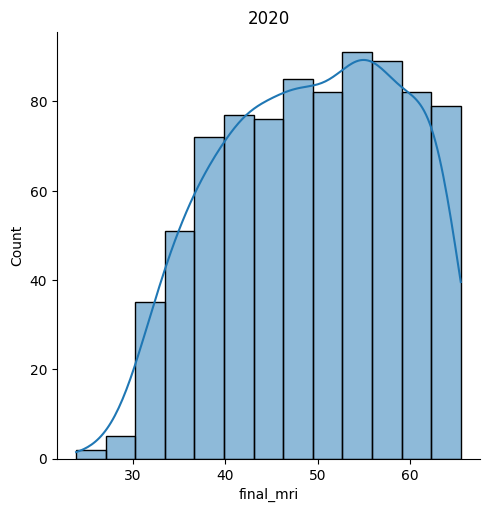

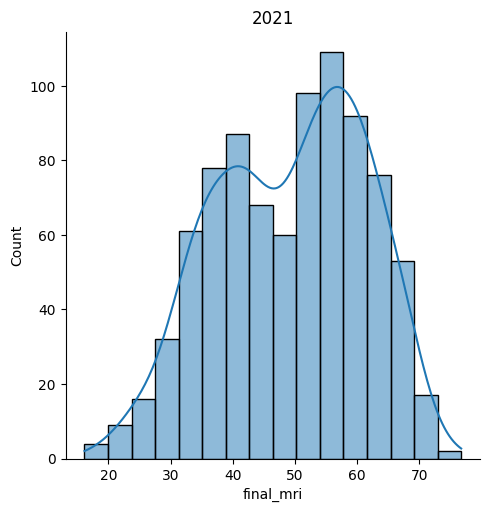

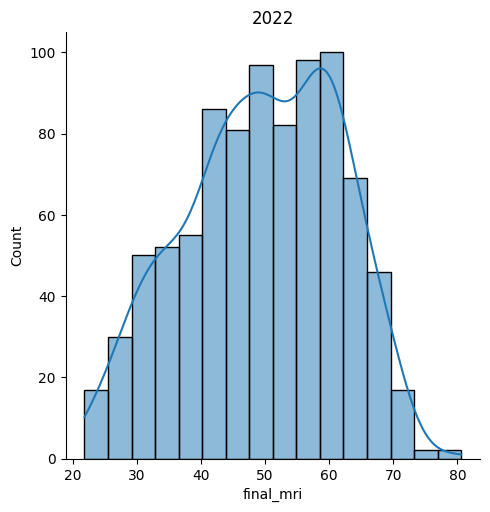

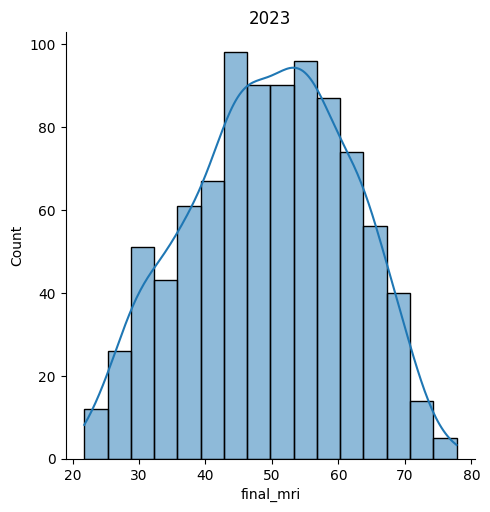

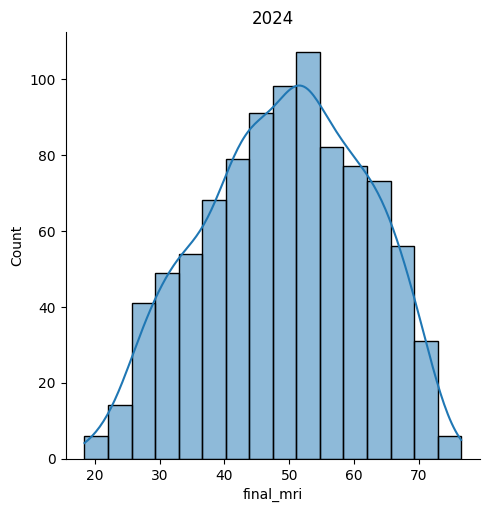

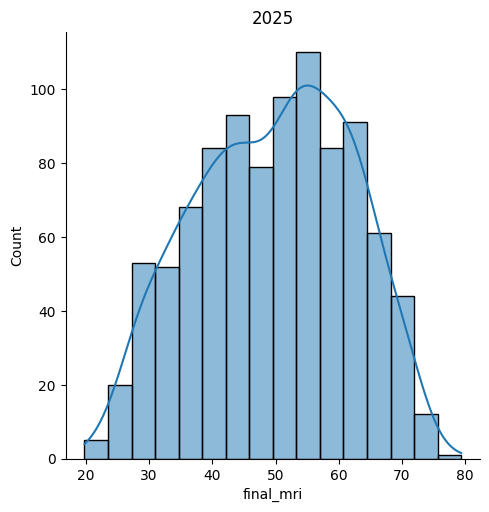

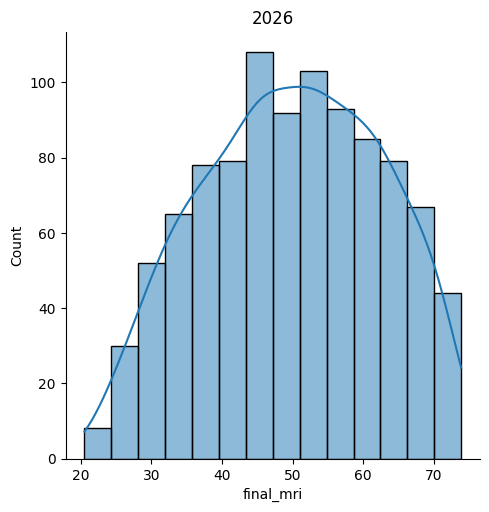

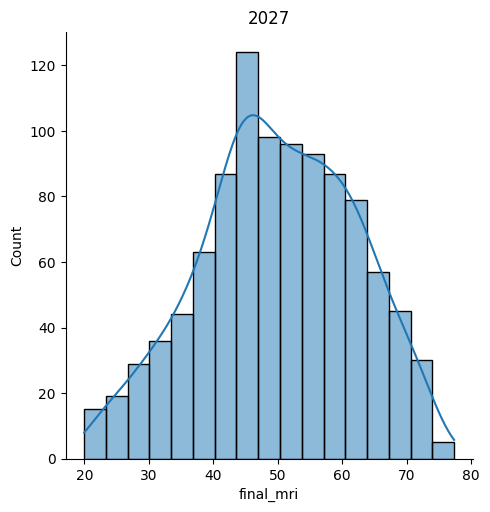

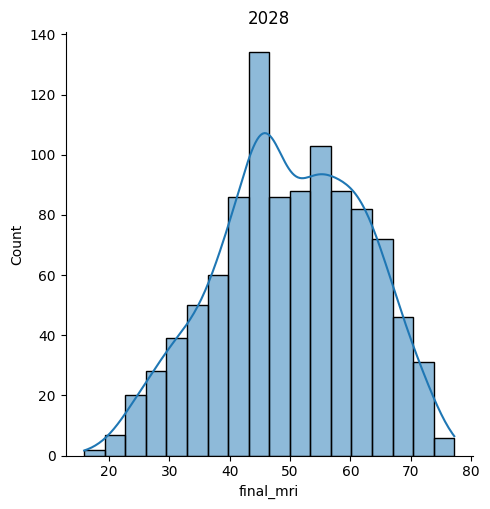

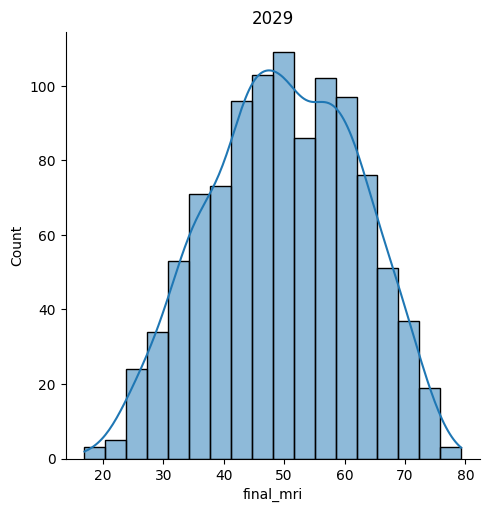

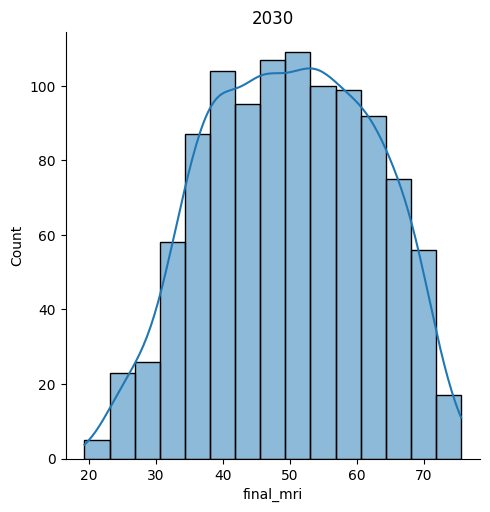

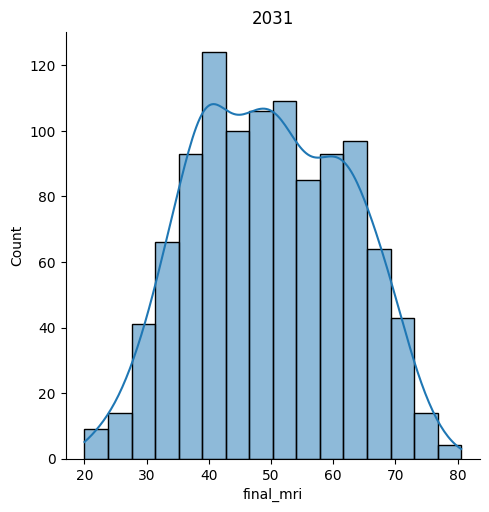

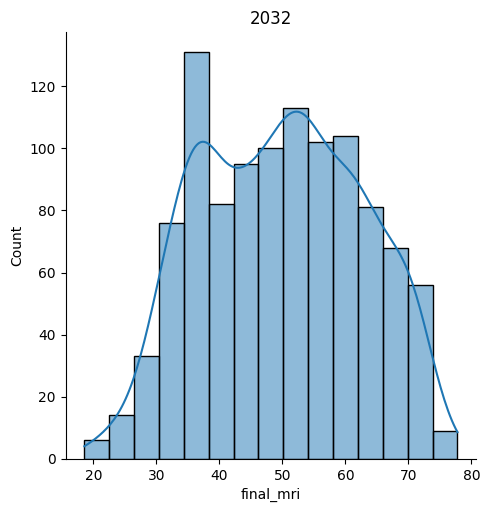

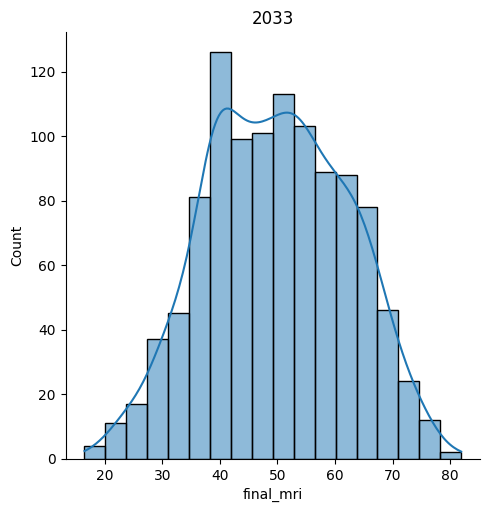

In [67]:
for s in sorted(set(submarket_df_w_index.year)):
    temp = submarket_df_w_index[submarket_df_w_index['year'] == s]
    sns.displot(data=temp, x="final_mri", kde=True)
    plt.title(s)
    plt.show()

In [70]:
plot_year = 2025

df_plot = submarket_df_w_index[submarket_df_w_index["year"] == plot_year].copy()

selected = pd.concat([
    df_plot.nlargest(1, "final_mri"),
    df_plot.nlargest(1, "growth_score"),
    df_plot.nlargest(1, "market_confidence"),
    df_plot.nsmallest(1, "final_mri")
]).drop_duplicates("submarket")

selected

,type,submarket,year,existing_auv,young_store_auv,maturity,number_of_existing_stores,new_auv,number_of_new,pipeline_auv,...,auv_cv_capped,store_count_confidence,market_confidence,auv_score,growth_score,future_store_share_score,market_consistency_score,raw_mri,system_avg_mri,final_mri
6193,submarket,Kansas City-Gladstone,2025,"[11550953.82, 12570051.85]",[],"[16, 11]",2,[None],1,[],...,0.042249,0.547723,0.740083,90.842105,98.051948,90.209424,58.105263,89.668106,50.041885,79.368570
12673,submarket,"Amarillo, TX-SE",2025,[],[6548564.03],[1],1,[],0,[],...,0.000000,0.316228,0.324668,4.526316,99.729437,42.198953,83.263158,44.728200,50.041885,48.316702
19,submarket,"Atlanta, GA-East Cobb County",2025,"[8986508.58, 11012289.709999999, 6404215.56000...",[],"[38, 38, 37, 32, 31, 29, 27, 26, 10, 10, 4]",11,[],0,[],...,0.237441,1.000000,1.000000,18.000000,66.774892,42.198953,13.157895,34.568152,50.041885,34.568152
1671,submarket,"Atlanta, GA-McDonough-Locust Grove",2025,"[7936772.3, 7663742.99, 9346384.55, 8510218.9,...","[6078085.239999999, 3347292.38]","[26, 19, 11, 3, 3, 1, 1]",7,[],0,[],...,0.273442,0.836660,0.822980,14.105263,4.112554,42.198953,7.684211,13.274714,50.041885,19.783236


In [71]:
selected_markets = []

selected_markets.append(
    submarket_df_w_index.loc[submarket_df_w_index["final_mri"].idxmax(), "submarket"]
)

growth = (
    submarket_df_w_index[~submarket_df_w_index["submarket"].isin(selected_markets)]
    .loc[:, :]
)
selected_markets.append(
    growth.loc[growth["growth_score"].idxmax(), "submarket"]
)

conf = (
    submarket_df_w_index[~submarket_df_w_index["submarket"].isin(selected_markets)]
)
selected_markets.append(
    conf.loc[conf["market_confidence"].idxmax(), "submarket"]
)

worst = (
    submarket_df_w_index[~submarket_df_w_index["submarket"].isin(selected_markets)]
)
selected_markets.append(
    worst.loc[worst["final_mri"].idxmin(), "submarket"]
)

selected_markets

['Orlando-Theme Parks',
 'Denver-Westminster',
 'Atlanta, GA-East Cobb County',
 'Chicago-Naperville']

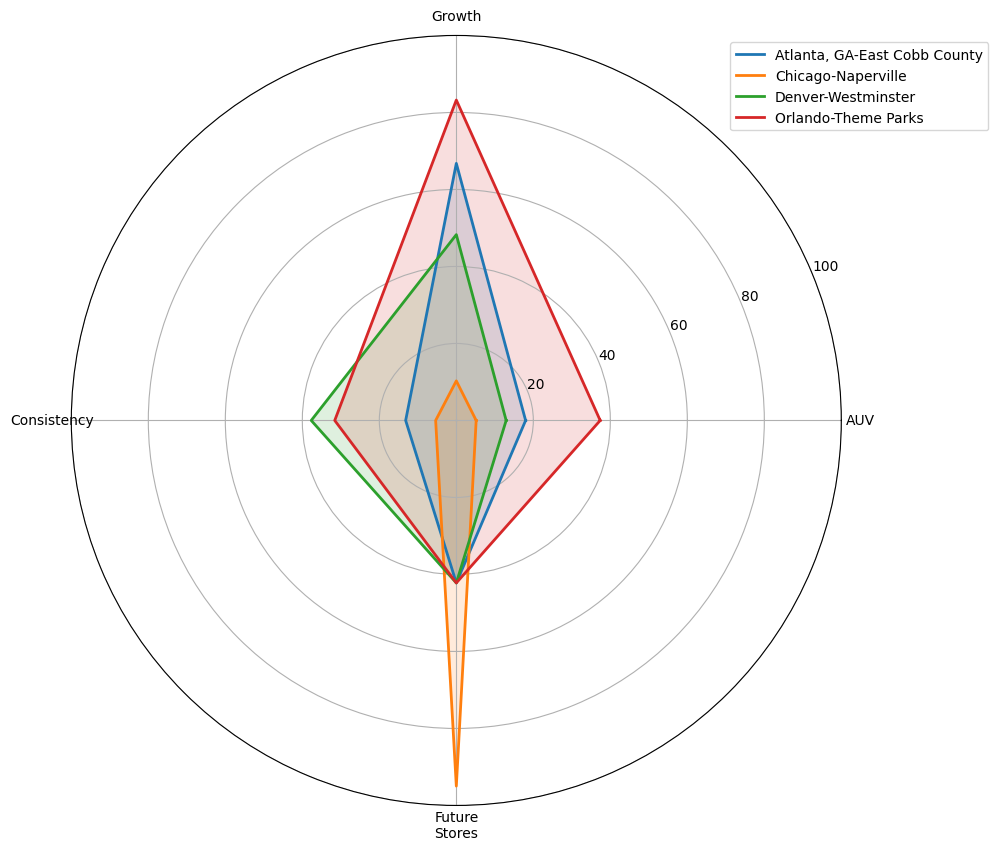

In [72]:
import matplotlib.pyplot as plt
import numpy as np

cols = [
    "auv_score",
    "growth_score",
    "market_consistency_score",
    "future_store_share_score"
]

labels = [
    "AUV",
    "Growth",
    "Consistency",
    "Future\nStores"
]

plot_df = (
    df_plot[df_plot["submarket"].isin(selected_markets)]
    .set_index("submarket")
)

N = len(labels)

angles = np.linspace(0, 2*np.pi, N, endpoint=False)
angles = np.concatenate([angles, [angles[0]]])

fig = plt.figure(figsize=(10,10))
ax = plt.subplot(111, polar=True)

for market in plot_df.index:

    values = plot_df.loc[market, cols].values.tolist()
    values += [values[0]]

    ax.plot(
        angles,
        values,
        linewidth=2,
        label=market
    )

    ax.fill(
        angles,
        values,
        alpha=.15
    )

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)

ax.set_ylim(0,100)

# plt.title(f"Market Component Comparison ({plot_year})")

plt.legend(
    bbox_to_anchor=(1.2,1)
)

plt.show()

In [73]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

plt.scatter(
    submarket_df_w_index["market_confidence"],
    submarket_df_w_index["final_mri"],
    alpha=.6
)

# highlight chosen markets
for _, row in submarket_df_w_index.iterrows():

    plt.scatter(
        row["market_confidence"],
        row["final_mri"],
        s=150
    )

    plt.text(
        row["market_confidence"]+0.01,
        row["final_mri"],
        row["submarket"],
        fontsize=9
    )

plt.xlabel("Market Confidence")
plt.ylabel("Final MRI")

plt.title(f"Final MRI vs Market Confidence ({plot_year})")

plt.grid(alpha=.3)

plt.show()


KeyboardInterrupt



Error in callback <function _draw_all_if_interactive at 0x0000027A48547D00> (for post_execute), with arguments args (),kwargs {}:



KeyboardInterrupt



Error in callback <function flush_figures at 0x0000027A45FC2A70> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

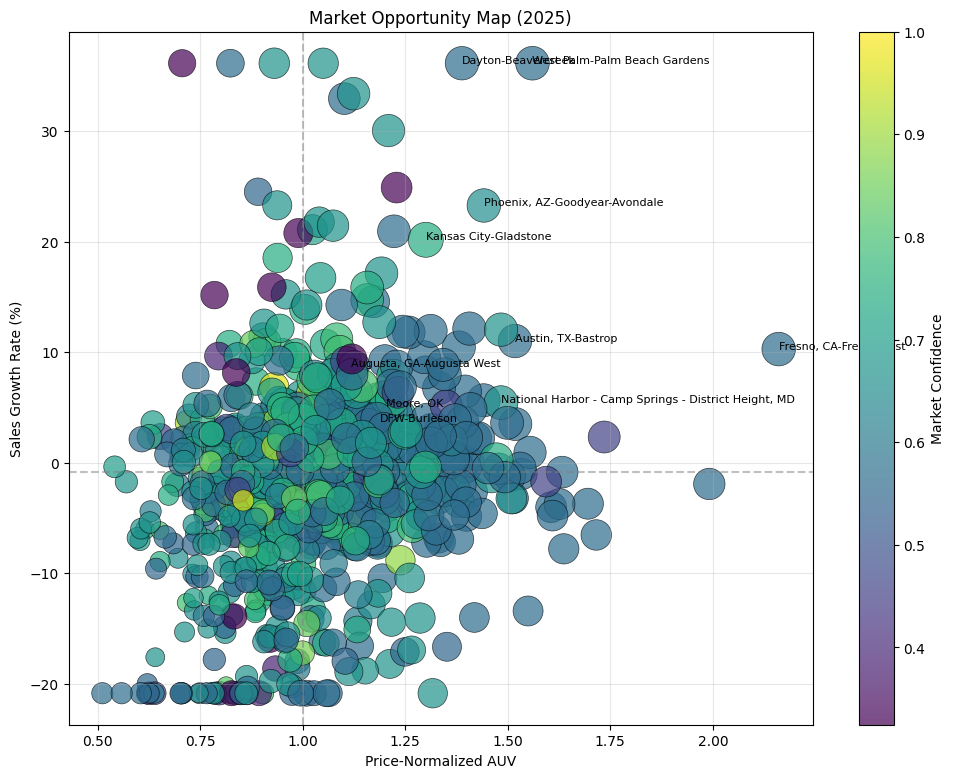

In [79]:
import matplotlib.pyplot as plt
import numpy as np

plot_year = 2025

plot_df = (
    submarket_df_w_index[submarket_df_w_index["year"] == plot_year]
    .copy()
)

# Bubble size
plot_df["bubble_size"] = (
    plot_df["final_mri"] * 8
)

plt.figure(figsize=(12, 9))

scatter = plt.scatter(
    plot_df["price_normalized_auv"],
    plot_df["growth_rate_selected"],   # convert to %
    s=plot_df["bubble_size"],
    c=plot_df["market_confidence"],
    cmap="viridis",
    alpha=0.7,
    edgecolors="black",
    linewidth=0.5
)

# Label top MRI markets
top = plot_df.nlargest(10, "final_mri")

for _, row in top.iterrows():
    plt.text(
        row["price_normalized_auv"],
        row["growth_rate_selected"],
        row["submarket"],
        fontsize=8
    )

plt.colorbar(scatter, label="Market Confidence")

plt.xlabel("Price-Normalized AUV")
plt.ylabel("Sales Growth Rate (%)")
plt.title(f"Market Opportunity Map ({plot_year})")

plt.grid(alpha=0.3)

# Optional quadrant lines
plt.axvline(
    plot_df["price_normalized_auv"].median(),
    color="gray",
    linestyle="--",
    alpha=0.5,
)

plt.axhline(
    plot_df["growth_rate_selected"].median(),
    color="gray",
    linestyle="--",
    alpha=0.5,
)

plt.show()

In [76]:
list(submarket_df_w_index.columns)

['type',
 'submarket',
 'year',
 'existing_auv',
 'young_store_auv',
 'maturity',
 'number_of_existing_stores',
 'new_auv',
 'number_of_new',
 'pipeline_auv',
 'number_of_pipeline',
 'strategy_auv',
 'number_of_strategy',
 'existing_auv_avg',
 'existing_auv_med',
 'young_store_auv_avg',
 'young_store_auv_med',
 'combined_auv',
 'existing_combined_auv',
 'combined_auv_avg',
 'combined_auv_med',
 'new_combined_auv',
 'maturity_avg',
 'matured_auv_avg',
 'new_auv_avg',
 'sales_growth_rate_matured',
 'sales_growth_rate_young_store',
 'sales_growth_rate_existing',
 'sales_growth_rate_new',
 'sales_growth_rate_combined',
 'number_of_new_stores',
 'combined_auv_mean',
 'combined_auv_median',
 'combined_auv_std',
 'combined_auv_cv',
 'combined_auv_count',
 'existing_combined_auv_mean',
 'existing_combined_auv_median',
 'existing_combined_auv_std',
 'existing_combined_auv_cv',
 'existing_combined_auv_count',
 'maturity_confidence',
 'total_store_count',
 'future_store_count',
 'future_store_sha

In [103]:
(5.2+6.3+6.1)/3, (2*6.2 + 5.1)/3

(5.866666666666667, 5.833333333333333)

In [104]:
5.87/5.83

1.006861063464837